# Original method vs. retraining BERT every round

**Question.** In the original method BERT is fine-tuned once and frozen, and the three self-training rounds only retrain the five MLPs. Does performance improve round by round if **BERT is also retrained on each round's pseudo-labels**?

**Two methods, same seeds, same round 0.**

| | Original method (paper) | Iterative variant (this experiment) |
|---|---|---|
| Round 0 | BERT fine-tuned on the labelled data, frozen; 5 MLPs on its embeddings | identical, shared |
| Each round 1–3 | selection on the current ensemble → retrain the 5 MLPs on the **same frozen embeddings** | selection on the current ensemble → **fine-tune a fresh BERT** on labelled data + the selected pseudo-labels → **recompute all embeddings and the graph** → retrain the 5 MLPs on the new embeddings |
| Selection | your paper's settings: calibration, BALD gate, alignment, adaptive thresholds, graph tier, class balancing, soft targets, weights | identical |

In each round of the iterative variant, BERT is trained from the pretrained checkpoint on the labelled rows plus that round's pseudo-labels, with their soft targets and weights. It uses the same recipe as the round-0 BERT.

**What the final chart shows** (one column per dataset, mean ± s.d. over seeds):
- **Rows:** pseudo-labels used per round, then validation macro-F1, then test macro-F1.
- **Lines:**
  - the original method's MLP ensemble;
  - the iterative variant's MLP ensemble;
  - the iterative variant's own BERT classifier (at round 0 this is the frozen BERT's classifier).

**Time on one T4 GPU:** about **1 h 50 min per seed** (Mody ~70 min, DynaHate ~30 min, Davidson ~10 min), so **~5.5 h** for seeds 42, 43 and 44. Seed 42 finishes first. Set `SEEDS = [42]` for a ~2 h first look.

**How to run.** Nothing in the code needs editing.
1. **Settings:** Accelerator → *GPU T4 ×1*; Internet → *On*.
2. **Add Input:** your `balanced_data.csv` dataset.
3. **Save Version → Save & Run All (Commit).**

**If it stops part-way:** run it again. Finished rounds are reused, and a BERT interrupted mid-training continues from its last finished epoch. In a new session, add the stopped version's output as an input.

**Send back:** `iterative/rounds.csv`, `iterative/summary.csv` and `iterative/rounds_chart.png` (inside `bert_once_cached_mlp/`), or the executed notebook.

In [1]:
# Install in the notebook's kernel. Keep the host-provided CUDA-compatible PyTorch.
%pip -q install "transformers==4.51.3" "huggingface-hub>=0.30,<1.0" "safetensors>=0.4" "scikit-learn>=1.5,<2" "scipy>=1.12,<2" "pandas>=2.2,<3" "matplotlib>=3.8,<4" "tqdm>=4.66" "nbformat>=5.10"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 96.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, math, time, random, hashlib, inspect, shutil, gc, platform
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from contextlib import contextmanager
from itertools import combinations
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.sparse import csr_matrix, diags, eye
from scipy.sparse.linalg import cg
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer, AutoConfig, AutoModelForSequenceClassification
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

assert tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2]) >= (2, 3), 'PyTorch >=2.3 required.'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| torch:', torch.__version__)
if DEVICE.type == 'cuda':
    print(torch.cuda.get_device_name(0), '| GPU GB:', round(torch.cuda.get_device_properties(0).total_memory/2**30, 1))
else:
    print('CPU is suitable for the small self-check only. Use a GPU for full experiments.')

from scipy.sparse import save_npz as sparse_save_npz, load_npz
from IPython.display import display


Device: cuda | torch: 2.10.0+cu128
Tesla T4 | GPU GB: 14.6


## Configuration
Keep the five member seeds: these train **small MLPs only**. `REPEAT_SEEDS=[42,43,44]` means three complete experiments. Each seed has its own BERT fit, calibration/stopping split and MLP seeds; the outer train/validation/U/test split stays fixed. Report the mean ± s.d. over seeds. BERT adaptation uses training labels only and an internal stopping holdout. The MLPs use separate cached embeddings, never encoder gradients.

Defaults match the original full policy's constants and 768–768–256 head, 80-epoch MLP cap, batch 256, AdamW and OneCycle schedule. Corrections retained from the reviewed implementation are: current-candidate neighbor agreement, zero certainty for disconnected graph nodes, a shared calibration holdout, and exclusion of validation/calibration/stopping rows from the graph. BERT adaptation uses AdamW at 2e-5 with warmup/cosine decay and up to five epochs; this is an additional supervised adaptation step. Thus these are not exact reruns of the historical frozen-SimCSE scores.

For a matched effect-of-adaptation comparison, uncomment `bert_unadapted_full` before running. It uses the same base BERT checkpoint without the initial fine-tuning. To compare SimCSE itself, set `model_name` to `princeton-nlp/sup-simcse-bert-base-uncased` for both matched configurations; do not interpret BERT-versus-SimCSE differences solely as fine-tuning effects.

**Selection policies.** `LENIENT` is the earlier policy, unchanged. `STRICT` (the new default, `BASE`) adds the acceptance rules described under *Full quality-aware selection*. Both share the same BERT fit, embeddings, graph and round-0 MLPs, because those caches are keyed only on the settings they depend on. Changing a selection setting therefore retrains only the MLPs of rounds 1–3. `REUSE_LEGACY=True` also imports these artefacts from an output of the previous notebook revision found under `ROOT` (via `RESUME_FROM`).


In [3]:
@dataclass(frozen=True)
class Config:
    model_name: str = 'bert-base-uncased'
    revision: str = 'main'  # resolved to an immutable local snapshot / commit before training
    member_seeds: tuple = (0, 1, 2, 3, 4)
    hidden: tuple = (768, 768, 256)
    dropout: float = 0.5
    max_length: int = 128
    micro_batch: int = 8
    accumulation: int = 4  # effective optimization batch approximately 32; BN sees micro_batch
    inference_batch: int = 32
    epochs: int = 5
    patience: int = 2
    encoder_lr: float = 2e-5
    weight_decay: float = 0.01
    grad_clip: float = 1.0
    gradient_checkpointing: bool = True
    amp: bool = True
    workers: int = 0
    rounds: int = 3
    split_seed: int = 42
    calibration_fraction: float = 0.10
    stopping_fraction: float = 0.10  # of the annotated fitting pool, not of the remainder
    calibration: bool = True
    alignment: bool = True
    adaptive_thresholds: bool = True
    disagreement: bool = True
    graph: bool = True
    class_balance: bool = True
    soft_targets: bool = True
    graded_weights: bool = True
    tau: float = 0.95
    tau_floor: float = 0.80
    disagreement_quantile: float = 0.75
    tier2_tau: float = 0.70
    lp_quantile: float = 0.50
    neighbor_agreement: float = 0.75
    min_neighbors: int = 2
    graph_k: int = 10
    graph_gamma: float = 3.0
    graph_chunk: int = 256
    lp_alpha: float = 0.99
    lp_maxiter: int = 1000
    target_temperature: float = 0.5
    tier2_weight: float = 0.75
    confidence_floor: float = 0.10
    flat_weight: float = 0.5
    ramp_length: int = 3
    # Strict acceptance. These defaults reproduce the earlier lenient policy; STRICT below switches them on.
    member_consensus: bool = False        # every MLP member must vote for the pseudo-label class
    label_stability: bool = False         # the class must match the previous round's prediction
    tier2_uncertainty_gate: bool = False  # tier 2 must also pass the tier-1 disagreement gate
    pseudo_mass_cap: float = None         # summed pseudo-label weight <= cap x annotated fitting rows


@dataclass(frozen=True)
class FastConfig(Config):
    adapt_encoder: bool = True
    mlp_epochs: int = 80
    mlp_patience: int = 12
    mlp_batch: int = 256
    mlp_lr: float = 1e-3
    feature_batch: int = 64


ROOT = Path('/kaggle/working/bert_once_cached_mlp') if Path('/kaggle').exists() else Path.cwd()/'bert_once_cached_mlp'
ROOT.mkdir(parents=True,exist_ok=True)
RESUME_FROM = None  # saved output folder, e.g. '/kaggle/input/my-output/bert_once_cached_mlp'
DATASETS = ['original','dynahate','davidson']
ORIGINAL_CSV = '/kaggle/input/datasets/parsadev/balanced-data/balanced_data.csv'
DYNAHATE_CSV = None
DAVIDSON_CSV = None
REPEAT_SEEDS = [42, 43, 44]  # each extra seed = one more BERT fit per dataset; [42] for a single run
OPEN_TEST = True  # False while tuning; True evaluates existing final heads with no refit.
LENIENT = FastConfig()  # earlier policy, unchanged
STRICT = replace(LENIENT, tau_floor=0.90, tier2_tau=0.85, neighbor_agreement=0.90, member_consensus=True,
                 label_stability=True, tier2_uncertainty_gate=True, pseudo_mass_cap=1.0)
BASE = STRICT
# Same BERT fit, embeddings, graph and round-0 MLPs for both; only rounds 1-3 differ.
EXPERIMENTS = {'bert_adapted_once_strict': STRICT, 'bert_adapted_once_full': LENIENT}
REUSE_LEGACY = True  # import BERT/embeddings/graph/round 0 from a previous-revision output under ROOT (RESUME_FROM)
# EXPERIMENTS['bert_unadapted_full'] = replace(BASE,adapt_encoder=False)
# Matched ablations reuse the cached BERT fit and retrain only MLPs:
# EXPERIMENTS['bert_no_graph'] = replace(BASE,graph=False)
# EXPERIMENTS['bert_no_disagreement'] = replace(BASE,disagreement=False)
# EXPERIMENTS['strict_no_mass_cap'] = replace(STRICT,pseudo_mass_cap=None)
# EXPERIMENTS['strict_no_stability'] = replace(STRICT,label_stability=False)
for cfg in EXPERIMENTS.values():
    assert len(cfg.member_seeds)>=2 and len(set(cfg.member_seeds))==len(cfg.member_seeds)
    assert cfg.epochs>=1 and cfg.mlp_epochs>=1 and cfg.rounds>=1
    assert cfg.micro_batch>=2 and cfg.accumulation>=1 and cfg.mlp_batch>=2
    assert cfg.calibration_fraction>0 and cfg.stopping_fraction>0
    assert cfg.calibration_fraction+cfg.stopping_fraction<1
    assert cfg.split_seed==BASE.split_seed
    assert cfg.tau_floor<=cfg.tau and (cfg.pseudo_mass_cap is None or cfg.pseudo_mass_cap>0)
print('BERT fits per dataset/config/repeat:',int(BASE.adapt_encoder))
print('MLP ensemble members:',len(BASE.member_seeds),'| self-training rounds:',BASE.rounds)
print('Selection policies:',list(EXPERIMENTS))


BERT fits per dataset/config/repeat: 1
MLP ensemble members: 5 | self-training rounds: 3
Selection policies: ['bert_adapted_once_strict', 'bert_adapted_once_full']


In [4]:
# ---- Settings for this notebook (override the configuration above; the defaults need no editing) ----
SEEDS = [42, 43, 44]                      # [42] for a ~2 h first look
POLICY = 'bert_adapted_once_full'          # your paper's selection settings (lenient)
EXPERIMENTS = {POLICY: LENIENT}            # the original method; the strict policy is not needed here
DATASETS = ['davidson', 'dynahate', 'original']  # smallest first, so results appear early
REPEAT_SEEDS = SEEDS
INPUT_ROOTS = [Path('/kaggle/input'), Path('/content')]
OUTPUT_DIRS = ('bert_once_cached_mlp', 'student_ssl')  # reported, never searched inside

def walk_inputs():
    # Every folder under the input roots, FOLLOWING symbolic links (Kaggle mounts inputs through links).
    seen = set()
    for root in INPUT_ROOTS:
        if not root.exists(): continue
        for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
            real = os.path.realpath(dirpath)
            if real in seen: dirnames[:] = []; continue
            seen.add(real)
            if Path(dirpath).name in OUTPUT_DIRS: dirnames[:] = []
            yield Path(dirpath), dirnames, filenames

# Original corpus: the attached balanced_data.csv, wherever Kaggle mounted it.
csvs = sorted({os.path.realpath(d/f): d/f for d, _, files in walk_inputs() for f in files if f.lower() == 'balanced_data.csv'}.values())
if csvs: ORIGINAL_CSV = str(csvs[0])
elif not Path(ORIGINAL_CSV).is_file():
    DATASETS = [d for d in DATASETS if d != 'original']
    print('WARNING: balanced_data.csv is not attached, so the Original corpus is skipped. Add Input -> your dataset.')
print('Original corpus:', ORIGINAL_CSV if 'original' in DATASETS else 'not attached')

# Resume across sessions: an attached earlier version of THIS notebook (its output holds bert_once_cached_mlp/).
previous = [d for d, _, _ in walk_inputs() if d.name == 'bert_once_cached_mlp' and (d/'runs').is_dir()]
if previous and RESUME_FROM is None:
    RESUME_FROM = str(previous[0]); print('Resuming from the attached earlier output:', RESUME_FROM)

Original corpus: /kaggle/input/datasets/parsadev/balanced-data/balanced_data.csv


## Reproducibility helpers and data

The Original corpus retains its provided two-class mapping and prints it. DynaHate is downsampled equally across hate / not-hate. Davidson merges original classes 0 and 1 (hate/offensive) against class 2 (neither), then balances. Splits use the supplied notebook's order: test 20%, unlabeled 80% of development, validation 20% of the remaining annotated pool. Text cleaning removes URLs, replaces user mentions, and collapses whitespace.

Each run then reserves **10% calibration + 10% early stopping** from its annotated fitting pool, shared across all members. During development that pool is `train`; for final refitting it is `train + validation`. Calibration and stopping data never seed the graph or enter gradient training. Labels of U are retained in the source dataset only for an optional retrospective diagnostic **after** the run, not passed into the SSL runner.

The internal stopping and calibration roles each reserve 10% of the annotated training pool. Neither participates in BERT gradient updates. The stopping role selects the BERT epoch and each MLP epoch; outer validation remains separate. Calibration is reused across self-training rounds and indirectly influences later pseudo-labels, so calibration-holdout diagnostics would not independently establish calibration generalization. No test text is encoded before test evaluation.


In [5]:
EPS = 1e-12
ENGINE_REVISION = 'bert-quality-aware-v1'

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()

def array_digest(x):
    x = np.ascontiguousarray(x)
    return hashlib.sha256(str(x.dtype).encode()+str(x.shape).encode()+x.tobytes()).hexdigest()

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str))
    os.replace(tmp, path)

def read_json(path):
    return json.loads(Path(path).read_text())

def save_npz(path, **arrays):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp')
    with tmp.open('wb') as f: np.savez_compressed(f, **arrays)
    os.replace(tmp, path)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def release_gpu():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def sync_gpu():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

@contextmanager
def timed_section():
    sync_gpu(); t = time.perf_counter(); record = {}
    yield record
    sync_gpu(); record['seconds'] = time.perf_counter()-t

def environment():
    import importlib.metadata as md
    return {'python': platform.python_version(), 'platform': platform.platform(),
            'packages': {p: md.version(p) for p in ['torch','transformers','numpy','pandas','scikit-learn','scipy']},
            'device': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None}

if RESUME_FROM:
    source = Path(RESUME_FROM)
    assert source.exists() and source.resolve() != ROOT.resolve()
    for p in source.rglob('*'):
        if p.is_file():
            q = ROOT / p.relative_to(source)
            if not q.exists(): q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p,q)
write_json(ROOT/'environment_current.json', environment())

def find_csv(explicit, names):
    if explicit:
        p=Path(explicit)
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    found=[]
    for root in [Path('/kaggle/input'), Path('/content')]:
        if root.exists(): found.extend(p for p in root.rglob('*.csv') if p.name.lower() in names)
    if len(found)>1: raise ValueError(f'Multiple matching CSVs; set an explicit path: {found}')
    return found[0] if found else None

def balanced(df, seed=42):
    n=int(df.y.value_counts().min())
    return pd.concat([g.sample(n=n,random_state=seed) for _,g in df.groupby('y')]).sample(frac=1,random_state=seed).reset_index(drop=True)

def load_data(name):
    if name=='original':
        p=find_csv(ORIGINAL_CSV, {'balanced_data.csv'})
        if p is None: raise FileNotFoundError('Attach balanced_data.csv or set ORIGINAL_CSV; public datasets can run without it.')
        raw=pd.read_csv(p).dropna(subset=['Content','Label']).reset_index(drop=True)
        encoder=LabelEncoder().fit(raw.Label)
        if len(encoder.classes_)!=2: raise ValueError('Original corpus must have exactly two labels.')
        df=pd.DataFrame({'text':raw.Content.astype(str), 'y':encoder.transform(raw.Label)})
        names=[str(x) for x in encoder.classes_]; source=str(p)
    elif name=='dynahate':
        url='https://raw.githubusercontent.com/bvidgen/Dynamically-Generated-Hate-Speech-Dataset/main/Dynamically%20Generated%20Hate%20Dataset%20v0.2.3.csv'
        p=find_csv(DYNAHATE_CSV, {'dynamically generated hate dataset v0.2.3.csv','dynahate.csv'})
        raw=pd.read_csv(p or url)
        tc=next((c for c in raw if c.lower() in {'text','content','comment','tweet','sentence'}),None)
        lc=next((c for c in raw if c.lower() in {'label','class','target','gold_label'}),None)
        if tc is None or lc is None: raise ValueError(f'Unrecognized DynaHate columns: {raw.columns.tolist()}')
        raw=raw.dropna(subset=[tc,lc])
        mapping={'hate':1,'hateful':1,'1':1,'1.0':1,'yes':1,'true':1,
                 'nothate':0,'not_hate':0,'not-hate':0,'not hate':0,'non-hate':0,'0':0,'0.0':0,'no':0,'false':0}
        labels=raw[lc].astype(str).str.strip().str.lower()
        if not set(labels).issubset(mapping): raise ValueError(f'Unrecognized DynaHate labels: {set(labels)-set(mapping)}')
        df=balanced(pd.DataFrame({'text':raw[tc].astype(str).values,'y':labels.map(mapping).values}))
        names=['Not hate','Hate']; source=str(p or url)
    elif name=='davidson':
        url='https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/master/data/labeled_data.csv'
        p=find_csv(DAVIDSON_CSV, {'labeled_data.csv','davidson.csv'})
        raw=pd.read_csv(p or url).dropna(subset=['tweet','class'])
        cls=raw['class'].astype(int)
        if not set(cls).issubset({0,1,2}): raise ValueError('Unexpected Davidson class values.')
        df=balanced(pd.DataFrame({'text':raw.tweet.astype(str).values,'y':(cls!=2).astype(int).values}))
        names=['Neither','Offensive or hateful']; source=str(p or url)
    else: raise ValueError(name)
    df=df.reset_index(drop=True); df['row_id']=np.arange(len(df))
    return df, {'source':source,'class_names':names,'retained_rows':len(df),
                'data_hash':digest(df[['text','y']].values.tolist())}

def clean_text(text):
    t=re.sub(r'http\S+|www\.\S+', ' ', str(text))
    t=re.sub(r'@\w+', ' @user ', t)
    return re.sub(r'\s+', ' ', t).strip() or '[empty]'

def split_data(df, seed=42):
    dev,test=train_test_split(df,test_size=.20,stratify=df.y,random_state=seed)
    annotated,unl=train_test_split(dev,test_size=.80,stratify=dev.y,random_state=seed)
    train,val=train_test_split(annotated,test_size=.20,stratify=annotated.y,random_state=seed)
    return {k:v.reset_index(drop=True) for k,v in {'train':train,'val':val,'unl':unl,'test':test}.items()}

def overlap_audit(parts):
    groups={k:set(v.text.map(clean_text).str.casefold()) for k,v in parts.items()}
    return {f'{a}__{b}':len(groups[a]&groups[b]) for a,b in combinations(groups,2)}

RAW, PARTS, DATA_META = {}, {}, {}
for name in DATASETS:
    df,meta=load_data(name); parts=split_data(df,BASE.split_seed)
    audit=overlap_audit(parts)
    meta.update(split_seed=BASE.split_seed, splits={k:v.row_id.tolist() for k,v in parts.items()}, exact_text_overlap=audit)
    RAW[name],PARTS[name],DATA_META[name]=df,parts,meta
    write_json(ROOT/'data'/f'{name}_manifest.json',meta)
    print(name, {k:len(v) for k,v in parts.items()}, '| classes:',meta['class_names'])
    print('Normalized exact-text overlaps:',audit)
    if any(audit.values()): print('Overlap exists: treat legacy-split results as exploratory; use grouped splits for confirmation.')


davidson {'train': 1065, 'val': 267, 'unl': 5328, 'test': 1666} | classes: ['Neither', 'Offensive or hateful']
Normalized exact-text overlaps: {'train__val': 0, 'train__unl': 8, 'train__test': 2, 'val__unl': 1, 'val__test': 0, 'unl__test': 10}
Overlap exists: treat legacy-split results as exploratory; use grouped splits for confirmation.
dynahate {'train': 4856, 'val': 1214, 'unl': 24280, 'test': 7588} | classes: ['Not hate', 'Hate']
Normalized exact-text overlaps: {'train__val': 0, 'train__unl': 5, 'train__test': 3, 'val__unl': 2, 'val__test': 0, 'unl__test': 8}
Overlap exists: treat legacy-split results as exploratory; use grouped splits for confirmation.
original {'train': 8556, 'val': 2139, 'unl': 42781, 'test': 13369} | classes: ['0', '1']
Normalized exact-text overlaps: {'train__val': 38, 'train__unl': 778, 'train__test': 239, 'val__unl': 207, 'val__test': 66, 'unl__test': 1150}
Overlap exists: treat legacy-split results as exploratory; use grouped splits for confirmation.


## Full quality-aware selection

BALD-inspired disagreement is `H(mean member probability) - mean(H(member probability))`, computed from raw member probabilities. It is an ensemble disagreement proxy, not proof of a Bayesian posterior or a decomposition into genuinely irreducible noise.

Tier 1 uses aligned, calibrated confidence with class-adaptive thresholds in [0.80, 0.95] and disagreement at or below the 75th percentile. Tier 2 applies to samples not accepted by tier 1: class agreement with label propagation, confidence ≥0.70, positive LP certainty at/above its median, ≥2 known neighbors and ≥0.75 neighbor agreement. Tier 2 does not impose the tier-1 disagreement gate. Previously accepted pseudo-labels supply neighborhood evidence only; propagation seeds remain fitting ground-truth labels. All selected samples may be removed or relabelled next round.

Because the encoder is fixed after one adaptation, graph geometry and label propagation are calculated once. Neighbor evidence is updated using the current accepted pseudo-labels each round. Disagreement is between the five MLP predictions and does not quantify uncertainty over BERT encoder parameters.

### Strict acceptance (`STRICT`, the default)
The lenient policy accepted samples the ensemble was only moderately sure about. Strict acceptance uses the same signals but requires them to agree:
- **Higher floor.** Class-adaptive thresholds may fall only to 0.90 (was 0.80); the ceiling stays 0.95.
- **Ensemble consensus.** All five MLP members must predict the pseudo-label class, so one dissenting member vetoes it. This is uncertainty-aware selection in the spirit of UPS (Rizve et al., 2021).
- **Cross-round stability.** From the second selection onward, a sample whose predicted class changed since the previous round is rejected (temporal-consistency filtering; cf. Zhou et al., 2020).
- **Tier 2 is no longer a bypass.** It needs confidence ≥0.85 and neighbour agreement ≥0.90. It must also pass the same disagreement, consensus and stability gates as tier 1. The graph is built from the same embeddings as the MLPs, so it is supporting evidence, not independent evidence.
- **Annotated data stays the anchor.** After confidence, tier and ramp weighting, the summed pseudo-label weight is scaled down when needed so that it never exceeds the number of annotated fitting rows (1×). This is analogous to bounding the unlabeled-loss weight λu in FixMatch.

Each rule is a flag (`member_consensus`, `label_stability`, `tier2_uncertainty_gate`, `pseudo_mass_cap`) or an existing constant (`tau_floor`, `tier2_tau`, `neighbor_agreement`), so each can be ablated with `replace(STRICT, ...)`. With all flags off, `select_full` behaves exactly as before.


In [6]:
def entropy(P):
    P=np.clip(np.asarray(P,dtype=np.float64),EPS,1.)
    return -(P*np.log(P)).sum(-1)

def probabilities(P):
    P=np.clip(np.asarray(P,dtype=np.float64),EPS,None)
    return P/P.sum(-1,keepdims=True)

def temperature_apply(P,T):
    z=np.log(np.clip(P,EPS,1.))/T; z-=z.max(-1,keepdims=True)
    return probabilities(np.exp(z))

def temperature_fit(P,y):
    y=np.asarray(y,dtype=int)
    def loss(T): return -np.log(np.clip(temperature_apply(P,T)[np.arange(len(y)),y],EPS,1.)).mean()
    opt=minimize_scalar(loss,bounds=(.25,8.),method='bounded')
    return float(min([1.,float(opt.x)],key=loss))

def disagreement_score(members):
    mean=np.asarray(members,dtype=np.float64).mean(0)
    return mean,np.maximum(entropy(mean)-entropy(members).mean(0),0.)

def align_probabilities(P,prior):
    return probabilities(P*(np.asarray(prior)/np.clip(P.mean(0),EPS,None)))

def adaptive_thresholds(P,cfg):
    conf,pred=P.max(1),P.argmax(1)
    counts=np.bincount(pred[conf>=cfg.tau],minlength=2).astype(float)
    return np.clip(cfg.tau*counts/max(counts.max(),1.),cfg.tau_floor,cfg.tau)

def sharpen_targets(P,T): return probabilities(np.clip(P,EPS,1.)**(1./T))

def ramp_weight(r,cfg):
    return float(np.exp(-5*(1-min(r/cfg.ramp_length,1.))**2))

def build_graph(X,cfg):
    X=np.asarray(X,dtype=np.float32)
    X=X/np.clip(np.linalg.norm(X,axis=1,keepdims=True),EPS,None)
    n=len(X); k=min(cfg.graph_k,n-1)
    if k<1: raise ValueError('At least two graph nodes required.')
    rows=np.repeat(np.arange(n),k); cols=np.empty(n*k,dtype=np.int64); vals=np.empty(n*k,np.float32)
    xt=torch.as_tensor(X,device=DEVICE)
    for s in range(0,n,cfg.graph_chunk):
        e=min(s+cfg.graph_chunk,n); sim=xt[s:e]@xt.T
        sim[torch.arange(e-s,device=DEVICE),torch.arange(s,e,device=DEVICE)]=-2.
        v,i=torch.topk(sim,k,dim=1)
        cols[s*k:e*k]=i.cpu().numpy().ravel()
        vals[s*k:e*k]=np.maximum(v.cpu().numpy(),0.).ravel()**cfg.graph_gamma
    del xt,sim; release_gpu()
    W=csr_matrix((vals,(rows,cols)),shape=(n,n)); W=W.maximum(W.T)
    W.setdiag(0); W.eliminate_zeros()
    return W

def propagate_labels(W,seed_y,cfg):
    n=W.shape[0]; degree=np.asarray(W.sum(1)).ravel()
    D=diags(1./np.sqrt(np.clip(degree,EPS,None)))
    A=(eye(n,format='csr')-cfg.lp_alpha*(D@W@D)).tocsr()
    targets=np.zeros((n,2)); targets[np.arange(len(seed_y)),seed_y]=1.
    result=np.zeros_like(targets)
    for c in range(2):
        result[:,c],info=cg(A,targets[:,c],rtol=1e-6,atol=0.,maxiter=cfg.lp_maxiter)
        if info!=0: raise RuntimeError(f'Label propagation did not converge (info={info}); inspect the graph.')
    result=np.clip(result,0.,None); reached=result.sum(1)>EPS
    P=np.full((n,2),.5); P[reached]=probabilities(result[reached])
    certainty=np.clip(1-entropy(P)/np.log(2),0.,1.); certainty[~reached]=0.
    return P,certainty

def neighbor_evidence(W,known_labels,known_mask,candidate_classes,unl_nodes):
    # Important correction: index counts by CURRENT candidate class, not stored self-label.
    binary=(W>0).astype(np.float32)
    onehot=np.zeros((W.shape[0],2),np.float32)
    ids=np.flatnonzero(known_mask); onehot[ids,known_labels[ids]]=1.
    counts=np.asarray(binary@onehot); total=counts.sum(1)
    agreed=counts[unl_nodes,candidate_classes]
    return agreed/np.maximum(total[unl_nodes],1.),total[unl_nodes]

def select_full(P,disagreement,cfg,lp=None,certainty=None,agreement=None,neighbor_count=None,
                members=None,previous_pred=None):
    conf,pred=P.max(1),P.argmax(1)
    tau=adaptive_thresholds(P,cfg) if cfg.adaptive_thresholds else np.full(2,cfg.tau)
    # Strict gates shared by both tiers; everything passes them under the lenient policy.
    trusted=np.ones(len(P),bool)
    if cfg.member_consensus:
        assert members is not None, 'member_consensus needs the raw member probabilities.'
        trusted &= (np.asarray(members).argmax(-1)==pred[None]).all(0)
    if cfg.label_stability and previous_pred is not None: trusted &= pred==np.asarray(previous_pred)
    certain=np.ones(len(P),bool)
    if cfg.disagreement: certain=disagreement<=np.quantile(disagreement,cfg.disagreement_quantile)
    t1=(conf>=tau[pred])&certain&trusted
    t2=np.zeros(len(P),bool)
    if cfg.graph:
        assert all(v is not None for v in [lp,certainty,agreement,neighbor_count])
        t2=(~t1)&(lp.argmax(1)==pred)&(conf>=cfg.tier2_tau)&trusted
        t2 &= (certainty>EPS)&(certainty>=np.quantile(certainty,cfg.lp_quantile))
        t2 &= (agreement>=cfg.neighbor_agreement)&(neighbor_count>=cfg.min_neighbors)
        if cfg.tier2_uncertainty_gate: t2 &= certain
    tier=np.where(t1,1,np.where(t2,2,0)); accepted=tier>0
    if cfg.class_balance and accepted.any():
        counts=np.bincount(pred[accepted],minlength=2)
        if counts.min()>0:
            take=np.zeros(len(P),bool)
            for c in range(2):
                ids=np.flatnonzero(accepted&(pred==c))
                ids=ids[np.argsort(-conf[ids],kind='stable')[:counts.min()]]; take[ids]=True
            accepted=take; tier=np.where(accepted,tier,0)
    return accepted,pred,tier,tau

def make_targets_weights(P,accepted,tier,r,cfg):
    target=sharpen_targets(P,cfg.target_temperature) if cfg.soft_targets else np.eye(2)[P.argmax(1)]
    if cfg.graded_weights:
        weight=ramp_weight(r,cfg)*np.clip(2*P.max(1)-1,cfg.confidence_floor,1.)
        weight*=np.where(tier==2,cfg.tier2_weight,1.)
    else: weight=np.full(len(P),cfg.flat_weight)
    return target.astype(np.float32),np.where(accepted,weight,0.).astype(np.float32)

def cap_pseudo_mass(weights,accepted,n_annotated,cfg):
    # Scale pseudo-label weights down (never up) so their sum is at most cap x annotated fitting rows.
    if cfg.pseudo_mass_cap is None or not accepted.any(): return weights
    total=float(weights[accepted].sum()); limit=cfg.pseudo_mass_cap*n_annotated
    return (weights*min(1.,limit/max(total,EPS))).astype(np.float32)


In [7]:
class SafeBatchNorm(nn.BatchNorm1d):
    def forward(self,x):
        if self.training and x.shape[0]==1:
            return F.batch_norm(x,self.running_mean,self.running_var,self.weight,self.bias,False,0.,self.eps)
        return super().forward(x)


class TokenRows(Dataset):
    def __init__(self,tokens,ids,targets=None,weights=None):
        self.tokens=tokens; self.ids=np.asarray(ids,dtype=int)
        self.targets=targets; self.weights=weights
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        row={k:v[self.ids[i]] for k,v in self.tokens.items()}
        if self.targets is None: return row
        return row,torch.as_tensor(self.targets[i],dtype=torch.float32),torch.tensor(self.weights[i],dtype=torch.float32)


def amp_context(cfg):
    return torch.autocast(device_type=DEVICE.type,dtype=torch.float16 if DEVICE.type=='cuda' else torch.bfloat16,
                          enabled=cfg.amp and DEVICE.type=='cuda')


def token_batch(batch): return {k:v.to(DEVICE,non_blocking=True) for k,v in batch.items()}


def metric_values(y,P):
    y=np.asarray(y,dtype=int); pred=P.argmax(1)
    return {'accuracy':float(accuracy_score(y,pred)), 'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
            'roc_auc':float(roc_auc_score(y,P[:,1])) if len(np.unique(y))==2 else None}


def calibration_metrics(y,P):
    conf=P.max(1); correct=(P.argmax(1)==y); ece=0.
    for low,high in zip(np.linspace(0,1,16)[:-1],np.linspace(0,1,16)[1:]):
        mask=(conf>low)&(conf<=high)
        if mask.any(): ece+=mask.mean()*abs(conf[mask].mean()-correct[mask].mean())
    return {'nll':float(-np.log(np.clip(P[np.arange(len(y)),y],EPS,1.)).mean()),'ece':float(ece)}

def model_snapshot(cfg):
    return snapshot_download(cfg.model_name,revision=cfg.revision,
        allow_patterns=['config.json','model.safetensors','model.safetensors.index.json','model-*.safetensors',
                        'pytorch_model.bin','pytorch_model.bin.index.json','pytorch_model-*.bin',
                        'tokenizer.json','tokenizer_config.json','special_tokens_map.json','vocab.txt','added_tokens.json'])


def make_roles(parts,cfg,repeat_seed,phase):
    lab=parts['train'] if phase=='development' else pd.concat([parts['train'],parts['val']],ignore_index=True)
    lab=lab.reset_index(drop=True)
    remaining,cal=train_test_split(np.arange(len(lab)),test_size=cfg.calibration_fraction,
                                  stratify=lab.y,random_state=repeat_seed)
    fit,stop=train_test_split(remaining,test_size=cfg.stopping_fraction/(1-cfg.calibration_fraction),
                              stratify=lab.y.values[remaining],random_state=repeat_seed+1)
    # Local node order: fit, U, stopping, calibration, outer validation (development only).
    frames=[lab.iloc[fit],parts['unl'],lab.iloc[stop],lab.iloc[cal]]
    keys=['fit','unl','stop','cal']
    if phase=='development': frames.append(parts['val']); keys.append('val')
    text=[]; role={}; provenance={}; offset=0
    for key,frame in zip(keys,frames):
        role[key]=np.arange(offset,offset+len(frame)); offset+=len(frame)
        text.extend(frame.text.map(clean_text).tolist()); provenance[key]=frame.row_id.tolist()
    labels={'fit':lab.y.values[fit].astype(int),'stop':lab.y.values[stop].astype(int),
            'cal':lab.y.values[cal].astype(int)}
    if phase=='development': labels['val']=parts['val'].y.values.astype(int)
    # No U or test label array is returned to the training runner.
    assert set(labels)==({'fit','stop','cal','val'} if phase=='development' else {'fit','stop','cal'})
    return text,role,labels,provenance


def encode_tokens(texts,snapshot,cfg):
    tok=AutoTokenizer.from_pretrained(snapshot,local_files_only=True)
    encoded=tok(texts,padding='max_length',truncation=True,max_length=cfg.max_length,return_tensors='pt')
    return {k:v for k,v in encoded.items() if k in {'input_ids','attention_mask','token_type_ids'}}

def bootstrap_f1(y,pred,n_boot=2000,seed=42):
    y=np.asarray(y); pred=np.asarray(pred); rng=np.random.default_rng(seed); scores=[]
    for _ in range(n_boot):
        idx=rng.integers(0,len(y),len(y)); yy=y[idx]; pp=pred[idx]
        # Binary macro-F1 with both labels retained, even if a resample lacks a class.
        f=[]
        for c in [0,1]:
            tp=np.sum((yy==c)&(pp==c)); fp=np.sum((yy!=c)&(pp==c)); fn=np.sum((yy==c)&(pp!=c))
            denominator=2*tp+fp+fn; f.append(2*tp/denominator if denominator else 0.)
        scores.append(np.mean(f))
    return np.quantile(scores,[.025,.975]).tolist()


## One encoder adaptation, cached features, then MLP-only training
The encoder is fully trainable during its single labeled-data adaptation. It is loaded in evaluation mode with gradients disabled for feature extraction. No BERT object is used in the MLP training function. Every MLP round starts with fresh seeded heads and fits its standardization on the actual fitting rows for that round. Soft pseudo-labels receive the same quality-dependent weighting as in the full framework. Only the final MLP ensemble supplies the reported predictions.

**Caching.** BERT adaptation, train/validation and test embeddings, the graph/propagation and the round-0 MLPs live under `ROOT/cache/<dataset>/encoder_<key>/`. That key covers only the data, split, model commit, encoder settings and encoder code. Selection settings and selection code are deliberately excluded, so every policy and ablation reuses one BERT fit and one embedding pass, and round 0 is shared. Rounds 1–3 are stored per run under `ROOT/runs/`. Tokenization is skipped when the BERT outputs are already cached. With `REUSE_LEGACY=True`, outputs from the previous notebook revision (code hash `14f60e36d58ba47f1b5d`) are hard-linked into this cache. A few rows are re-encoded first to confirm that they match. Completed MLP members are also resumed. An interrupted individual fit restarts that fit; save the complete output directory, including checkpoints. The manifest includes code/configuration/data identities. BERT timing includes its full adaptation, while the other timing columns cover the named operations only; their sum excludes data/model downloads, tokenization and some prediction/selection overhead and is not a full end-to-end timer.


In [8]:
# Engine embedded into the self-contained notebook by the builder.

@torch.no_grad()
def teacher_probs(model,tokens,ids,cfg):
    model.eval(); result=[]
    for s in range(0,len(ids),cfg.inference_batch):
        b={k:v[ids[s:s+cfg.inference_batch]].to(DEVICE) for k,v in tokens.items()}
        with amp_context(cfg): logits=model(**b).logits
        result.append(logits.float().softmax(-1).cpu().numpy())
    return np.vstack(result)

def adapt_once(cfg,snapshot,tokens,roles,y,seed,path):
    path=Path(path); path.mkdir(parents=True,exist_ok=True)
    marker=path/'complete.json'
    if marker.exists(): return read_json(marker)
    seed_all(seed); release_gpu()
    if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
    with timed_section() as timer:
        model=AutoModelForSequenceClassification.from_pretrained(snapshot,num_labels=2,local_files_only=True).to(DEVICE)
        if cfg.gradient_checkpointing: model.gradient_checkpointing_enable()
        opt=torch.optim.AdamW(model.parameters(),lr=cfg.encoder_lr,weight_decay=cfg.weight_decay)
        ids=roles['fit']; targets=np.eye(2,dtype=np.float32)[y['fit']]
        loader=DataLoader(TokenRows(tokens,ids,targets,np.ones(len(ids))),batch_size=cfg.micro_batch,
            shuffle=True,generator=torch.Generator().manual_seed(seed),num_workers=0)
        steps=math.ceil(len(loader)/cfg.accumulation)*cfg.epochs
        warmup=max(1,int(.1*steps))
        def factor(s):
            return (s+1)/warmup if s<warmup else .5*(1+math.cos(math.pi*min((s-warmup)/max(steps-warmup,1),1)))
        sched=torch.optim.lr_scheduler.LambdaLR(opt,factor)
        scaler=torch.amp.GradScaler('cuda',enabled=cfg.amp and DEVICE.type=='cuda')
        best=-1.; bad=0; history=[]
        for epoch in range(1,cfg.epochs+1):
            model.train(); opt.zero_grad(set_to_none=True)
            for step,(batch,target,_) in enumerate(tqdm(loader,desc=f'BERT once: epoch {epoch}/{cfg.epochs}',leave=False)):
                start=(step//cfg.accumulation)*cfg.accumulation
                end=min(start+cfg.accumulation,len(loader))
                count=min(end*cfg.micro_batch,len(ids))-start*cfg.micro_batch
                with amp_context(cfg):
                    logits=model(**token_batch(batch)).logits
                    loss=F.cross_entropy(logits.float(),target.argmax(-1).to(DEVICE),reduction='sum')/count
                if not torch.isfinite(loss): raise FloatingPointError('Non-finite BERT loss')
                scaler.scale(loss).backward()
                if step+1==end:
                    scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(),cfg.grad_clip)
                    scale=scaler.get_scale(); scaler.step(opt); scaler.update()
                    if scaler.get_scale()>=scale: sched.step()
                    opt.zero_grad(set_to_none=True)
            score=metric_values(y['stop'],teacher_probs(model,tokens,roles['stop'],cfg))['accuracy']
            history.append({'epoch':epoch,'stopping_accuracy':score})
            print('BERT adaptation',epoch,'stopping accuracy',round(score,4))
            if score>best:
                best=score; bad=0; model.save_pretrained(path/'best',safe_serialization=True)
            else:
                bad+=1
                if bad>=cfg.patience: break
        params=sum(p.numel() for p in model.parameters() if p.requires_grad)
        peak=torch.cuda.max_memory_allocated()/2**30 if DEVICE.type=='cuda' else None
        del model,opt,sched,scaler; release_gpu()
    result={'seconds':timer['seconds'],'history':history,'bert_fits':1,'trainable_params':params,
            'peak_training_gpu_allocated_gb':peak,'environment':environment()}
    write_json(marker,result); return result

@torch.no_grad()
def cached_features(tokens,cfg,encoder_path,path):
    path=Path(path); meta_path=path.with_suffix('.json')
    if path.exists() and meta_path.exists(): return np.load(path,mmap_mode='r'),read_json(meta_path)
    with timed_section() as timer:
        model=AutoModel.from_pretrained(encoder_path,local_files_only=True,add_pooling_layer=False).to(DEVICE).eval()
        for p in model.parameters(): p.requires_grad_(False)
        features=[]; n=len(next(iter(tokens.values())))
        for s in tqdm(range(0,n,cfg.feature_batch),desc='Cache frozen BERT embeddings',leave=False):
            b={k:v[s:s+cfg.feature_batch].to(DEVICE) for k,v in tokens.items()}
            with amp_context(cfg):
                h=model(**b).last_hidden_state
                mask=b['attention_mask'].unsqueeze(-1).to(h.dtype)
                pooled=(h*mask).sum(1)/mask.sum(1).clamp_min(1)
            features.append(pooled.float().cpu().numpy())
        X=np.vstack(features)
        tmp=path.with_suffix('.tmp')
        with tmp.open('wb') as f: np.save(f,X)
        os.replace(tmp,path)
        del model,features; release_gpu()
    meta={'seconds':timer['seconds'],'shape':list(X.shape),'encoder_trainable':False}
    write_json(meta_path,meta); return np.load(path,mmap_mode='r'),meta

class CachedMLP(nn.Module):
    def __init__(self,d,cfg):
        super().__init__(); layers=[]; prev=d
        for width in cfg.hidden:
            layers.extend([nn.Linear(prev,width),SafeBatchNorm(width),nn.GELU(),nn.Dropout(cfg.dropout)])
            prev=width
        layers.append(nn.Linear(prev,2)); self.head=nn.Sequential(*layers)
        self.register_buffer('mean',torch.zeros(d)); self.register_buffer('scale',torch.ones(d))
    def forward(self,x): return self.head((x-self.mean)/self.scale)

@torch.no_grad()
def mlp_probs(model,X,ids,batch=4096):
    model.eval(); results=[]
    for s in range(0,len(ids),batch):
        x=torch.as_tensor(np.array(X[ids[s:s+batch]],copy=True),dtype=torch.float32,device=DEVICE)
        results.append(model(x).softmax(-1).cpu().numpy())
    return np.vstack(results)

def fit_mlp(X,ids,targets,weights,roles,y,cfg,seed,path):
    path=Path(path); path.mkdir(parents=True,exist_ok=True)
    if (path/'complete.json').exists() and (path/'weights.pt').exists(): return read_json(path/'complete.json')
    seed_all(seed); release_gpu()
    with timed_section() as timer:
        model=CachedMLP(X.shape[1],cfg).to(DEVICE)
        train=np.array(X[ids],dtype=np.float32,copy=True)
        mean=train.mean(0,dtype=np.float64); scale=train.std(0,dtype=np.float64); scale[scale<1e-8]=1
        model.mean.copy_(torch.as_tensor(mean,dtype=torch.float32,device=DEVICE))
        model.scale.copy_(torch.as_tensor(scale,dtype=torch.float32,device=DEVICE))
        # Entire feature matrix for this fit fits comfortably in GPU memory on a T4.
        xx=torch.as_tensor(train,device=DEVICE); yy=torch.as_tensor(targets,device=DEVICE)
        ww=torch.as_tensor(weights,device=DEVICE)
        opt=torch.optim.AdamW(model.parameters(),lr=cfg.mlp_lr,weight_decay=cfg.weight_decay)
        steps=math.ceil(len(ids)/cfg.mlp_batch)*cfg.mlp_epochs
        # Match the original MLP schedule; tiny smoke runs use a constant schedule.
        sched=(torch.optim.lr_scheduler.OneCycleLR(opt,max_lr=cfg.mlp_lr,total_steps=steps,pct_start=.15)
               if steps>=20 else torch.optim.lr_scheduler.LambdaLR(opt,lambda s:1.))
        best=-1.; bad=0; history=[]
        for epoch in range(1,cfg.mlp_epochs+1):
            model.train(); order=torch.randperm(len(ids),device=DEVICE); total=0.
            for s in range(0,len(ids),cfg.mlp_batch):
                idx=order[s:s+cfg.mlp_batch]; opt.zero_grad(set_to_none=True)
                logits=model(xx[idx]); loss=(-(yy[idx]*F.log_softmax(logits,-1)).sum(-1)*ww[idx]).mean()
                if not torch.isfinite(loss): raise FloatingPointError('Non-finite MLP loss')
                loss.backward(); opt.step(); sched.step(); total+=float(loss.detach())*len(idx)
            score=metric_values(y['stop'],mlp_probs(model,X,roles['stop']))['accuracy']
            history.append({'epoch':epoch,'loss':total/len(ids),'stopping_accuracy':score})
            if score>best:
                best=score; bad=0
                tmp=path/'weights.tmp'; torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},tmp)
                os.replace(tmp,path/'weights.pt')
            else:
                bad+=1
                if bad>=cfg.mlp_patience: break
        params=sum(p.numel() for p in model.parameters())
        del model,opt,sched,xx,yy,ww; release_gpu()
    result={'seconds':timer['seconds'],'history':history,'trainable_params':params,'seed':seed,'environment':environment()}
    write_json(path/'complete.json',result)
    print(path.name,'MLP epochs:',len(history),'seconds:',round(result['seconds'],1))
    return result

def mlp_stage(X,ids,targets,weights,roles,y,cfg,repeat_seed,path):
    path=Path(path); path.mkdir(parents=True,exist_ok=True)
    if (path/'complete.json').exists():
        with np.load(path/'probabilities.npz') as z: predictions={k:z[k] for k in z.files}
        return predictions,read_json(path/'complete.json')
    members=[]; stats=[]
    for m,offset in enumerate(cfg.member_seeds):
        dest=path/f'member_{m}'
        stats.append(fit_mlp(X,ids,targets,weights,roles,y,cfg,repeat_seed*100+offset,dest))
        model=CachedMLP(X.shape[1],cfg).to(DEVICE)
        model.load_state_dict(torch.load(dest/'weights.pt',map_location=DEVICE,weights_only=True))
        members.append({key:mlp_probs(model,X,roles[key]) for key in ['unl','cal','val']})
        del model; release_gpu()
    predictions={key:np.stack([m[key] for m in members]) for key in members[0]}
    save_npz(path/'probabilities.npz',**predictions)
    result={'members':stats,'pseudo_labels':len(ids)-len(roles['fit'])}
    write_json(path/'complete.json',result); return predictions,result

ENCODER_FIELDS=('model_name','revision','max_length','micro_batch','accumulation','inference_batch','epochs',
    'patience','encoder_lr','weight_decay','grad_clip','gradient_checkpointing','amp','workers','split_seed',
    'calibration_fraction','stopping_fraction','adapt_encoder','feature_batch')
GRAPH_FIELDS=('graph_k','graph_gamma','graph_chunk','lp_alpha','lp_maxiter')
MLP_FIELDS=('member_seeds','hidden','dropout','weight_decay','mlp_epochs','mlp_patience','mlp_batch','mlp_lr')
# Previous notebook revision; its encoder, embedding, graph and MLP code is identical to this one.
LEGACY_IMPLEMENTATIONS=('14f60e36d58ba47f1b5d',)

def subset(config,fields): return {k:config.get(k) for k in fields}

def cache_dirs(dataset,cfg,repeat_seed,snapshot):
    # Selection settings are deliberately absent: every policy shares BERT, embeddings, graph and round 0.
    c=asdict(cfg); meta=DATA_META[dataset]
    key={'dataset':dataset,'data':meta['data_hash'],'splits':digest(meta['splits']),'repeat_seed':repeat_seed,
         'model_commit':Path(snapshot).name,'config':subset(c,ENCODER_FIELDS),'code':CODE_HASHES['encoder']}
    enc_dir=ROOT/'cache'/dataset/f'encoder_{digest(key)[:16]}'
    graph_dir=enc_dir/f"graph_{digest([subset(c,GRAPH_FIELDS),CODE_HASHES['graph']])[:12]}"
    stage0_dir=enc_dir/f"round0_{digest([subset(c,MLP_FIELDS),CODE_HASHES['mlp']])[:12]}"
    return enc_dir,graph_dir,stage0_dir

def link_file(src,dst):
    dst=Path(dst)
    if dst.exists(): return
    dst.parent.mkdir(parents=True,exist_ok=True); tmp=dst.with_name(dst.name+'.tmp')
    if tmp.exists(): tmp.unlink()
    try: os.link(src,tmp)  # hard link: no extra disk space for the 440 MB BERT checkpoint
    except OSError: shutil.copy2(src,tmp)
    os.replace(tmp,dst)

def link_tree(src,dst,skip=()):
    files=[p for p in Path(src).rglob('*') if p.is_file() and p.name not in skip]
    markers=sorted([p for p in files if p.name=='complete.json'],key=lambda p:-len(p.parts))
    for p in [p for p in files if p.name!='complete.json']+markers:  # completion markers last
        link_file(p,Path(dst)/p.relative_to(src))

def import_legacy(dataset,cfg,repeat_seed,snapshot,enc_dir,graph_dir,stage0_dir):
    """Reuse BERT adaptation, embeddings, graph and round 0 from a previous-revision run under ROOT/runs."""
    reused=[]
    if not REUSE_LEGACY: return reused
    c=asdict(cfg); meta=DATA_META[dataset]
    for manifest in sorted((ROOT/'runs'/dataset).glob('*/*/manifest.json')):
        old_dir=manifest.parent; old=read_json(manifest); oc=old.get('config',{}); od=old.get('data',{})
        if not (str(old.get('implementation',''))[:20] in LEGACY_IMPLEMENTATIONS and old.get('repeat_seed')==repeat_seed
                and old.get('model_commit')==Path(snapshot).name and od.get('data_hash')==meta['data_hash']
                and digest(od.get('splits'))==digest(meta['splits'])
                and digest(subset(oc,ENCODER_FIELDS))==digest(subset(c,ENCODER_FIELDS))): continue
        found=[]
        if cfg.adapt_encoder and not (enc_dir/'adaptation'/'complete.json').exists() \
                and (old_dir/'adaptation'/'complete.json').exists():
            link_tree(old_dir/'adaptation',enc_dir/'adaptation'); found.append('BERT adaptation')
        for old_name,new_name in [('embeddings','embeddings'),('test/embeddings','test_embeddings')]:
            a,b=old_dir/old_name,enc_dir/new_name
            if not b.with_suffix('.json').exists() and a.with_suffix('.json').exists() and a.with_suffix('.npy').exists():
                link_file(a.with_suffix('.npy'),b.with_suffix('.npy')); link_file(a.with_suffix('.json'),b.with_suffix('.json'))
                found.append(new_name)
        if cfg.graph and oc.get('graph') and digest(subset(oc,GRAPH_FIELDS))==digest(subset(c,GRAPH_FIELDS)) \
                and not (graph_dir/'complete.json').exists() and (old_dir/'graph_complete.json').exists():
            link_file(old_dir/'graph.npz',graph_dir/'graph.npz'); link_file(old_dir/'propagation.npz',graph_dir/'propagation.npz')
            link_file(old_dir/'graph_complete.json',graph_dir/'complete.json'); found.append('graph')
        if digest(subset(oc,MLP_FIELDS))==digest(subset(c,MLP_FIELDS)) and not (stage0_dir/'complete.json').exists() \
                and (old_dir/'stage_0'/'complete.json').exists():
            link_tree(old_dir/'stage_0',stage0_dir,skip={'selection.npz'}); found.append('round-0 MLPs')
        if found: print('Reusing from previous run',old_dir.name+':',', '.join(found))
        reused+=found
    return reused

@torch.no_grad()
def embedding_agreement(texts,X,snapshot,cfg,encoder_path,n=16):
    # Re-encode a few rows to confirm reused embeddings come from this encoder and these rows.
    b={k:v.to(DEVICE) for k,v in encode_tokens(texts[:n],snapshot,cfg).items()}
    model=AutoModel.from_pretrained(encoder_path,local_files_only=True,add_pooling_layer=False).to(DEVICE).eval()
    with amp_context(cfg):
        h=model(**b).last_hidden_state; mask=b['attention_mask'].unsqueeze(-1).to(h.dtype)
        fresh=((h*mask).sum(1)/mask.sum(1).clamp_min(1)).float().cpu().numpy()
    del model; release_gpu()
    ref=np.asarray(X[:n],dtype=np.float32)
    return float(((fresh*ref).sum(1)/(np.linalg.norm(fresh,axis=1)*np.linalg.norm(ref,axis=1))).min())

def run_cached(dataset,label,cfg,repeat_seed):
    snapshot=model_snapshot(cfg)
    enc_dir,graph_dir,stage0_dir=cache_dirs(dataset,cfg,repeat_seed,snapshot)
    manifest={'version':'adapt-once-cache-mlp-v2','implementation':IMPLEMENTATION_HASH,
        'dataset':dataset,'label':label,'config':asdict(cfg),'repeat_seed':repeat_seed,
        'data':DATA_META[dataset],'model_commit':Path(snapshot).name,'packages':environment()['packages'],
        'shared_cache':str(enc_dir.relative_to(ROOT)),
        'test_rule':'prespecified final round; raw MLP ensemble mean argmax; no second encoder refit',
        'test_history':'legacy test sets already inspected; exploratory comparisons'}
    run_id=digest(manifest)[:20]; path=ROOT/'runs'/dataset/label/run_id; path.mkdir(parents=True,exist_ok=True)
    dirs={'run_dir':str(path),'encoder_dir':str(enc_dir),'stage0_dir':str(stage0_dir)}
    if (path/'complete.json').exists():
        result=read_json(path/'complete.json'); result.update(dirs)
        print('Using completed run:',dataset,label); return result
    write_json(path/'manifest.json',manifest)
    texts,roles,y,provenance=make_roles(PARTS[dataset],cfg,repeat_seed,'development')
    write_json(path/'roles.json',provenance)
    reused=import_legacy(dataset,cfg,repeat_seed,snapshot,enc_dir,graph_dir,stage0_dir)
    encoder_path=str(enc_dir/'adaptation'/'best') if cfg.adapt_encoder else snapshot
    cached=(enc_dir/'embeddings.json').exists() and (not cfg.adapt_encoder or (enc_dir/'adaptation'/'complete.json').exists())
    tokens=None if cached else encode_tokens(texts,snapshot,cfg)  # no tokenizing when BERT outputs are cached
    if cfg.adapt_encoder:
        adaptation=adapt_once(cfg,snapshot,tokens,roles,y,repeat_seed,enc_dir/'adaptation')
    else:
        adaptation={'seconds':0.,'bert_fits':0,'trainable_params':0}
    print(dataset,'BERT fits:',adaptation['bert_fits'],'(shared by all policies) — encoder stays frozen from here.')
    X,feature_meta=cached_features(tokens,cfg,encoder_path,enc_dir/'embeddings.npy')
    del tokens; release_gpu()
    if len(X)!=len(texts): raise RuntimeError(f'Cached embeddings have {len(X)} rows; this run expects {len(texts)}.')
    if 'embeddings' in reused:
        cosine=embedding_agreement(texts,X,snapshot,cfg,encoder_path)
        print('Reused embeddings: minimum cosine with a fresh re-encoding =',round(cosine,5))
        if cosine<.99:
            del X; shutil.rmtree(enc_dir)
            raise RuntimeError('Reused embeddings do not match; removed them. Set REUSE_LEGACY=False and rerun.')
    nfit=len(roles['fit']); n=len(roles['unl']); W=None; lp=certainty=None
    graph_meta={'seconds':0.}
    if cfg.graph:
        if (graph_dir/'complete.json').exists():
            W=load_npz(graph_dir/'graph.npz')
            with np.load(graph_dir/'propagation.npz') as z: lp,certainty=z['lp'],z['certainty']
            graph_meta=read_json(graph_dir/'complete.json')
        else:
            with timed_section() as graph_timer:
                W=build_graph(X[np.concatenate([roles['fit'],roles['unl']])],cfg)
                all_lp,all_cert=propagate_labels(W,y['fit'],cfg)
                lp,certainty=all_lp[nfit:],all_cert[nfit:]
            graph_dir.mkdir(parents=True,exist_ok=True)
            sparse_save_npz(graph_dir/'graph.npz',W); save_npz(graph_dir/'propagation.npz',lp=lp,certainty=certainty)
            graph_meta=graph_timer; write_json(graph_dir/'complete.json',graph_meta)
    prior=np.bincount(y['fit'],minlength=2)/len(y['fit'])
    previous=np.zeros(n,bool); previous_labels=np.zeros(n,int); previous_pred=None
    ids=roles['fit']; targets=np.eye(2,dtype=np.float32)[y['fit']]; weights=np.ones(nfit,np.float32)
    histories=[]; stage_stats=[]
    for stage in range(cfg.rounds+1):
        # Round 0 uses annotated rows only, so it is shared by every selection policy.
        stage_dir=stage0_dir if stage==0 else path/f'stage_{stage}'
        bundle,stats=mlp_stage(X,ids,targets,weights,roles,y,cfg,repeat_seed,stage_dir)
        stage_stats.append(stats)
        val=metric_values(y['val'],bundle['val'].mean(0))
        T=temperature_fit(bundle['cal'].mean(0),y['cal']) if cfg.calibration else 1.
        report={'round':stage,'pseudo_labels_used':int(previous.sum()),'temperature':T,
                **{f'val_{k}':v for k,v in val.items()}}
        histories.append(report)
        print(dataset,label,'round',stage,{k:v for k,v in report.items() if k!='temperature'})
        if stage==cfg.rounds: break
        mean,epi=disagreement_score(bundle['unl']); P=temperature_apply(mean,T)
        if cfg.alignment: P=align_probabilities(P,prior)
        agreement=count=None
        if cfg.graph:
            known=np.r_[np.ones(nfit,bool),previous]; labels=np.r_[y['fit'],previous_labels]
            agreement,count=neighbor_evidence(W,labels,known,P.argmax(1),np.arange(nfit,nfit+n))
        accepted,pseudo,tier,tau=select_full(P,epi,cfg,lp,certainty,agreement,count,
                                             members=bundle['unl'],previous_pred=previous_pred)
        soft,w=make_targets_weights(P,accepted,tier,stage+1,cfg)
        w=cap_pseudo_mass(w,accepted,nfit,cfg)
        save_npz(path/f'stage_{stage}'/'selection.npz',accepted=accepted,pseudo=pseudo,tier=tier,
                 soft_targets=soft,weights=w,disagreement=epi,probabilities=P,thresholds=tau)
        report.update(next_selected=int(accepted.sum()),tier1=int(((tier==1)&accepted).sum()),
                      tier2=int(((tier==2)&accepted).sum()),removed=int((previous&~accepted).sum()),
                      pseudo_weight=float(w[accepted].sum()))
        print('Next selection:',{k:report[k] for k in ['next_selected','tier1','tier2','removed']},
              '| pseudo weight / annotated rows:',round(report['pseudo_weight']/nfit,3))
        write_json(path/'history.json',histories)
        previous_pred=P.argmax(1)
        if not accepted.any(): break
        previous=accepted; previous_labels=pseudo
        ids=np.r_[roles['fit'],roles['unl'][accepted]]
        targets=np.vstack([np.eye(2,dtype=np.float32)[y['fit']],soft[accepted]])
        weights=np.r_[np.ones(nfit,np.float32),w[accepted]]
    result={'dataset':dataset,'experiment':label,'repeat_seed':repeat_seed,'run_id':run_id,**dirs,
        'model_commit':Path(snapshot).name,'selected_stage':stage,'pseudo_labels':int(previous.sum()),
        'bert_fits':adaptation['bert_fits'],'bert_training_seconds':adaptation['seconds'],
        'embedding_seconds':feature_meta['seconds'],'graph_seconds':graph_meta['seconds'],
        'mlp_training_seconds':sum(m['seconds'] for s in stage_stats for m in s['members']),
        'mlp_fits':sum(len(s['members']) for s in stage_stats),
        'history':histories,**{f'val_{k}':v for k,v in val.items()}}
    write_json(path/'history.json',histories); write_json(path/'complete.json',result)
    return result

def test_cached(run,cfg):
    assert OPEN_TEST, 'Enable OPEN_TEST only after fixing your configuration.'
    path=Path(run['run_dir']); manifest=read_json(path/'manifest.json')
    assert manifest['implementation']==IMPLEMENTATION_HASH
    assert digest(manifest['config'])==digest(asdict(cfg))
    assert digest(manifest['data'])==digest(DATA_META[run['dataset']])
    dest=path/'test'; dest.mkdir(exist_ok=True)
    if (dest/'metrics.json').exists(): return read_json(dest/'metrics.json')
    write_json(dest/'test_opened.json',{'run_id':run['run_id'],'utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime()),
        'rule':manifest['test_rule'],'test_history':manifest['test_history']})
    snapshot=model_snapshot(replace(cfg,revision=run['model_commit']))
    enc_dir=Path(run['encoder_dir']); test=PARTS[run['dataset']]['test']
    # Test embeddings are cached once per encoder and shared by every policy evaluated on it.
    tokens=None if (enc_dir/'test_embeddings.json').exists() else encode_tokens(test.text.map(clean_text).tolist(),snapshot,cfg)
    encoder_path=str(enc_dir/'adaptation'/'best') if cfg.adapt_encoder else snapshot
    X,_=cached_features(tokens,cfg,encoder_path,enc_dir/'test_embeddings.npy')
    if len(X)!=len(test): raise RuntimeError('Cached test embeddings do not match the test split.')
    selected=run['selected_stage']
    weights_dir=Path(run['stage0_dir']) if selected==0 else path/f'stage_{selected}'
    members=[]
    for m in range(len(cfg.member_seeds)):
        model=CachedMLP(X.shape[1],cfg).to(DEVICE)
        model.load_state_dict(torch.load(weights_dir/f'member_{m}'/'weights.pt',map_location=DEVICE,weights_only=True))
        members.append(mlp_probs(model,X,np.arange(len(test))))
        del model; release_gpu()
    P=np.stack(members).mean(0); pred=P.argmax(1); y=test.y.values.astype(int)
    low,high=bootstrap_f1(y,pred)
    result={k:v for k,v in run.items()
            if k not in ['history','run_dir','encoder_dir','stage0_dir'] and not k.startswith('val_')}
    result.update(metric_values(y,P),f1_ci_low=low,f1_ci_high=high,test_support=len(y))
    save_npz(dest/'predictions.npz',row_id=test.row_id.values,y_true=y,y_pred=pred,
             probabilities=P,member_probabilities=np.stack(members))
    names=DATA_META[run['dataset']]['class_names']
    pd.DataFrame(classification_report(y,pred,labels=[0,1],target_names=names,output_dict=True,zero_division=0)).T.to_csv(dest/'class_report.csv')
    pd.DataFrame(confusion_matrix(y,pred,labels=[0,1]),index=names,columns=names).to_csv(dest/'confusion_matrix.csv')
    write_json(dest/'metrics.json',result); return result


In [9]:
def self_checks():
    c=Config(graph=False,disagreement=False,adaptive_thresholds=False,class_balance=False,tau=.80)
    P=np.array([[.9,.1],[.2,.8],[.55,.45]])
    take,pred,tier,_=select_full(P,np.zeros(3),c)
    assert take.tolist()==[True,True,False]
    mean,ep=disagreement_score(np.stack([P,P])); assert np.allclose(ep,0.)
    _,ep=disagreement_score(np.array([[[.99,.01]],[[.01,.99]]])); assert ep[0]>.5
    y=np.array([0,1,1]); T=temperature_fit(P,y)
    assert calibration_metrics(y,temperature_apply(P,T))['nll']<=calibration_metrics(y,P)['nll']+1e-8
    W=csr_matrix(np.array([[0,1,1],[1,0,0],[1,0,0]],float))
    a,n=neighbor_evidence(W,np.array([0,1,1]),np.array([False,True,True]),np.array([1]),np.array([0]))
    assert a[0]==1 and n[0]==2, 'Candidate class must override stored label zero.'
    disconnected=csr_matrix(np.zeros((3,3)))
    lp,cert=propagate_labels(disconnected,np.array([1]),Config())
    assert np.allclose(lp[1:],.5) and np.allclose(cert[1:],0.)
    cfg=replace(c,graph=True,tau=.95)
    take,_,tiers,_=select_full(np.array([[.8,.2],[.2,.8]]),np.zeros(2),cfg,
        lp=np.array([[.9,.1],[.1,.9]]),certainty=np.ones(2),agreement=np.ones(2),neighbor_count=np.full(2,2))
    assert take.all() and (tiers==2).all()
    cfg=replace(c,class_balance=True)
    pp=np.array([[.95,.05],[.9,.1],[.1,.9]])
    take,cl,_,_=select_full(pp,np.zeros(3),cfg)
    assert np.bincount(cl[take],minlength=2).tolist()==[1,1]
    soft,weight=make_targets_weights(P,np.array([True,True,False]),np.array([1,2,0]),3,Config())
    assert np.allclose(soft.sum(1),1.) and weight[2]==0
    assert np.isclose(weight[1],.75*(2*.8-1))
    # Strict gates: one dissenting member, a flipped class, or a high-disagreement tier-2 sample is rejected.
    members=np.stack([P,P,np.array([[.4,.6],[.2,.8],[.55,.45]])])
    take,_,_,_=select_full(P,np.zeros(3),replace(c,member_consensus=True),members=members)
    assert take.tolist()==[False,True,False], 'One dissenting member must veto a pseudo-label.'
    take,_,_,_=select_full(P,np.zeros(3),replace(c,label_stability=True),previous_pred=np.array([0,0,0]))
    assert take.tolist()==[True,False,False], 'A class that flipped since last round must be rejected.'
    g=replace(c,graph=True,tau=.95,disagreement=True,tier2_uncertainty_gate=True)
    take,_,_,_=select_full(np.array([[.8,.2],[.2,.8]]),np.array([0.,1.]),g,lp=np.array([[.9,.1],[.1,.9]]),
        certainty=np.ones(2),agreement=np.ones(2),neighbor_count=np.full(2,2))
    assert take.tolist()==[True,False], 'Tier 2 must respect the disagreement gate in strict mode.'
    w=cap_pseudo_mass(np.array([1.,1.,1.,0.],np.float32),np.array([True,True,True,False]),2,replace(c,pseudo_mass_cap=1.))
    assert np.isclose(w[:3].sum(),2.) and w[3]==0
    assert cap_pseudo_mass(w,np.array([True,True,True,False]),2,c) is w
    print('Selection, calibration, strict-gate and graph self-checks passed.')
self_checks()


# Record executable source so notebook edits invalidate cached experiment identities.
def implementation_source(obj):
    if inspect.isclass(obj):
        return [(name,inspect.getsource(method)) for name,method in obj.__dict__.items() if inspect.isfunction(method)]
    return inspect.getsource(obj)
ENGINE_OBJECTS = [digest, array_digest, write_json, read_json, save_npz, seed_all, release_gpu, sync_gpu, timed_section, environment, find_csv, balanced, load_data, clean_text, split_data, overlap_audit, entropy, probabilities, temperature_apply, temperature_fit, disagreement_score, align_probabilities, adaptive_thresholds, sharpen_targets, ramp_weight, build_graph, propagate_labels, neighbor_evidence, select_full, make_targets_weights, cap_pseudo_mass, SafeBatchNorm, TokenRows, amp_context, token_batch, metric_values, calibration_metrics, model_snapshot, make_roles, encode_tokens, bootstrap_f1, teacher_probs, adapt_once, cached_features, CachedMLP, mlp_probs, fit_mlp, mlp_stage, subset, cache_dirs, link_file, link_tree, import_legacy, embedding_agreement, run_cached, test_cached]
IMPLEMENTATION_HASH=digest([implementation_source(obj) for obj in ENGINE_OBJECTS])
# Narrower identities for the shared caches: selection code is not part of them.
CODE_HASHES={name:digest([implementation_source(obj) for obj in objects]) for name,objects in {
    'encoder':[clean_text,make_roles,encode_tokens,TokenRows,amp_context,token_batch,metric_values,seed_all,
               teacher_probs,adapt_once,cached_features],
    'graph':[build_graph,propagate_labels],
    'mlp':[SafeBatchNorm,CachedMLP,mlp_probs,fit_mlp,mlp_stage,metric_values,seed_all]}.items()}
print('Implementation:',IMPLEMENTATION_HASH[:20],'| shared caches:',{k:v[:12] for k,v in CODE_HASHES.items()})


Selection, calibration, strict-gate and graph self-checks passed.
Implementation: a201e37ad89d9571ec49 | shared caches: {'encoder': '6bcea5aa08cf', 'graph': 'b32578897bd5', 'mlp': 'a835f3008165'}


## BERT helpers
Tokenisation, scoring and the resumable BERT fine-tuning (weighted soft targets) used for each round.

In [10]:
import traceback, io, contextlib
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()  # hides the expected "classifier newly initialised" notice for each fresh BERT

INFER_BATCH = 128   # scoring batch; scoring never changes training
TOKENS = {}
ITER_DIR = ROOT/'iterative'; ITER_DIR.mkdir(parents=True, exist_ok=True)
TITLES = {'original': 'Mody dataset', 'dynahate': 'DynaHate', 'davidson': 'Davidson (binary)'}

def load_arrays(path):
    # Dense arrays saved with save_npz. (The engine's own `load_npz` is scipy's sparse loader; keep it intact.)
    with np.load(path) as z: return {k: z[k] for k in z.files}

def atomic_torch_save(obj, path):
    # A crash mid-write leaves the previous file intact.
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    torch.save(obj, tmp); os.replace(tmp, path)

def autocast(enabled=True):
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16 if DEVICE.type == 'cuda' else torch.bfloat16,
                          enabled=enabled and DEVICE.type == 'cuda')

def ensemble_predict(directory, cfg, X, ids=None):
    # Mean probability of the saved MLP members in `directory`.
    ids = np.arange(len(X)) if ids is None else np.asarray(ids); P = []
    for m in range(len(cfg.member_seeds)):
        model = CachedMLP(X.shape[1], cfg).to(DEVICE)
        model.load_state_dict(torch.load(Path(directory)/f'member_{m}'/'weights.pt', map_location=DEVICE, weights_only=True))
        P.append(mlp_probs(model, X, ids)); del model
    release_gpu(); return np.stack(P).mean(0)

def test_round0(run, cfg):
    # Supervised-only MLP reference (from final.ipynb): the shared round-0 ensemble on test.
    stage0 = Path(run['stage0_dir']); cache = stage0/'test_metrics.json'
    if cache.exists(): return read_json(cache)
    X = np.load(Path(run['encoder_dir'])/'test_embeddings.npy', mmap_mode='r')  # written by test_cached
    test = PARTS[run['dataset']]['test']; y = test.y.values.astype(int)
    P = ensemble_predict(stage0, cfg, X); low, high = bootstrap_f1(y, P.argmax(1))
    result = {'dataset': run['dataset'], 'experiment': 'round0_supervised', 'repeat_seed': run['repeat_seed'],
              'pseudo_labels': 0, **metric_values(y, P), 'f1_ci_low': low, 'f1_ci_high': high, 'test_support': len(y)}
    write_json(cache, result); return result

@torch.no_grad()
def embed_and_score(model, tokens, ids, amp=True):
    # One pass of a BERT classifier: masked-mean sentence vectors of its final layer (the engine's pooling) and its
    # own class probabilities, in the order of `ids` (row ids). Trailing padding is dropped, which changes nothing.
    model.eval(); ids = torch.as_tensor(np.asarray(ids, dtype=np.int64), device=DEVICE)
    order = torch.argsort(tokens['attention_mask'][ids].sum(1))
    emb = torch.empty((len(ids), model.config.hidden_size), dtype=torch.float32, device=DEVICE)
    prob = torch.empty((len(ids), 2), dtype=torch.float32, device=DEVICE)
    for s in range(0, len(ids), INFER_BATCH):
        pos = order[s:s+INFER_BATCH]; b = take(tokens, ids[pos])
        with autocast(amp):
            out = model(**b, output_hidden_states=True)
            h = out.hidden_states[-1]; m = b['attention_mask'].unsqueeze(-1).to(h.dtype)
            emb[pos] = ((h*m).sum(1)/m.sum(1).clamp_min(1)).float()
            prob[pos] = out.logits.float().softmax(-1)
    return emb.cpu().numpy(), prob.cpu().numpy()

# ---- The following are copied unchanged from the BERT-student notebook ----

def tokens_for(dataset, snapshot, max_length):
    # Every row of the dataset, tokenised once exactly as for the teacher, kept on the GPU and addressed by row_id.
    if (dataset, snapshot, max_length) not in TOKENS:
        tok = AutoTokenizer.from_pretrained(snapshot, local_files_only=True)
        enc = tok(RAW[dataset].text.map(clean_text).tolist(), padding='max_length', truncation=True,
                  max_length=max_length, return_tensors='pt')
        TOKENS[dataset, snapshot, max_length] = {k: v.to(DEVICE) for k, v in enc.items()
                                                 if k in ('input_ids', 'attention_mask', 'token_type_ids')}
    return TOKENS[dataset, snapshot, max_length]

def take(tokens, rows):
    # Rows are right-padded, so dropping the trailing all-padding columns gives the same outputs with less work.
    batch = {k: v[rows] for k, v in tokens.items()}
    width = int(batch['attention_mask'].sum(1).max())
    return {k: v[:, :width] for k, v in batch.items()}

@torch.no_grad()
def bert_probs(model, tokens, ids, amp=True):
    # Class probabilities in the order of `ids`; rows of similar length are scored together.
    model.eval(); ids = torch.as_tensor(np.asarray(ids, dtype=np.int64), device=DEVICE)
    order = torch.argsort(tokens['attention_mask'][ids].sum(1))
    out = torch.empty((len(ids), 2), dtype=torch.float32, device=DEVICE)
    for s in range(0, len(ids), INFER_BATCH):
        pos = order[s:s+INFER_BATCH]
        with autocast(amp): out[pos] = model(**take(tokens, ids[pos])).logits.float().softmax(-1)
    return out.cpu().numpy()

def train_student(job, snapshot, tokens, roles, y, ids, targets, weights, out_dir):
    # The teacher's recipe (adapt_once) on labelled + pseudo-labelled rows with weighted soft targets.
    # One optimiser step per micro_batch x accumulation rows, which is the teacher's effective batch. Gradient checkpointing
    # is off and trailing padding is dropped: both change speed, not the computation. The full training state is
    # saved after every epoch, so an interrupted run continues from its last finished epoch.
    cfg, seed = job['manifest']['config'], job['seed']
    ckpt, best_path, best_meta, done = out_dir/'last.pt', out_dir/'best.pt', out_dir/'best.json', out_dir/'train_done.json'
    if done.exists(): return read_json(done)
    batch, n, use_amp = int(cfg['micro_batch'])*int(cfg['accumulation']), len(ids), bool(cfg['amp']) and DEVICE.type == 'cuda'
    seed_all(seed)
    model = AutoModelForSequenceClassification.from_pretrained(snapshot, num_labels=2, local_files_only=True).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['encoder_lr'], weight_decay=cfg['weight_decay'])
    steps = math.ceil(n/batch)*cfg['epochs']; warmup = max(1, int(.1*steps))
    def factor(s):
        return (s+1)/warmup if s < warmup else .5*(1+math.cos(math.pi*min((s-warmup)/max(steps-warmup, 1), 1)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, factor)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    gen = torch.Generator().manual_seed(seed)
    state = {'epoch': 0, 'best': -1., 'best_epoch': 0, 'bad': 0, 'stopped': False, 'seconds': 0., 'history': []}
    if ckpt.exists():
        saved = torch.load(ckpt, map_location='cpu', weights_only=False)
        model.load_state_dict(saved['model']); opt.load_state_dict(saved['opt']); sched.load_state_dict(saved['sched'])
        scaler.load_state_dict(saved['scaler']); gen.set_state(saved['gen']); state = saved['state']
        torch.set_rng_state(saved['torch_rng']); np.random.set_state(saved['np_rng']); random.setstate(saved['py_rng'])
        if saved['cuda_rng'] is not None and torch.cuda.is_available(): torch.cuda.set_rng_state_all(saved['cuda_rng'])
        best_saved = read_json(best_meta)['epoch'] if best_meta.exists() else None
        if state['best_epoch'] == state['epoch'] and best_saved != state['epoch']:  # interrupted between the two saves
            atomic_torch_save({'epoch': state['epoch'], 'score': state['best'], 'state_dict': saved['model']}, best_path)
            write_json(best_meta, {'epoch': state['epoch'], 'score': state['best']})
        del saved
        print(f"  resuming after epoch {state['epoch']} (best stopping accuracy {state['best']:.4f})")
    ids_t = torch.as_tensor(np.asarray(ids, dtype=np.int64), device=DEVICE)
    targets_t = torch.as_tensor(targets, dtype=torch.float32, device=DEVICE)
    weights_t = torch.as_tensor(weights, dtype=torch.float32, device=DEVICE)
    while not state['stopped'] and state['epoch'] < cfg['epochs']:
        epoch = state['epoch']+1; t0 = time.time(); model.train(); opt.zero_grad(set_to_none=True)
        order = torch.randperm(n, generator=gen).to(DEVICE)
        for s in tqdm(range(0, n, batch), desc=f"student epoch {epoch}/{cfg['epochs']}", leave=False, mininterval=30):
            pos = order[s:s+batch]
            with autocast(use_amp): logits = model(**take(tokens, ids_t[pos])).logits
            per_row = -(targets_t[pos]*F.log_softmax(logits.float(), -1)).sum(-1)
            loss = (per_row*weights_t[pos]).sum()/len(pos)
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite student loss')
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            scale = scaler.get_scale(); scaler.step(opt); scaler.update()
            if scaler.get_scale() >= scale: sched.step()
            opt.zero_grad(set_to_none=True)
        score = metric_values(y['stop'], bert_probs(model, tokens, roles['stop'], use_amp))['accuracy']
        seconds = time.time()-t0; improved = score > state['best']
        state['history'].append({'epoch': epoch, 'stopping_accuracy': score, 'seconds': round(seconds, 1),
                                 'rows_per_second': round(n/seconds, 1)})
        state.update(epoch=epoch, seconds=state['seconds']+seconds)
        if improved: state.update(best=score, best_epoch=epoch, bad=0)
        else: state['bad'] += 1; state['stopped'] = state['bad'] >= cfg['patience']
        atomic_torch_save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                           'scaler': scaler.state_dict(), 'gen': gen.get_state(), 'torch_rng': torch.get_rng_state(),
                           'cuda_rng': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                           'np_rng': np.random.get_state(), 'py_rng': random.getstate(), 'state': state}, ckpt)
        if improved:
            atomic_torch_save({'epoch': epoch, 'score': score, 'state_dict': model.state_dict()}, best_path)
            write_json(best_meta, {'epoch': epoch, 'score': score})
        finished = state['stopped'] or epoch == cfg['epochs']
        print(f"  epoch {epoch}: stopping accuracy {score:.4f}{' (best)' if improved else ''} | {seconds/60:.1f} min, "
              f"{n/seconds:.0f} rows/s" + ('' if finished else f" | at most {(cfg['epochs']-epoch)*seconds/60:.0f} min left"))
    del model, opt, sched, scaler, ids_t, targets_t, weights_t; release_gpu()
    result = {'epochs_run': state['epoch'], 'best_epoch': state['best_epoch'], 'best_stopping_accuracy': state['best'],
              'train_seconds': state['seconds'], 'history': state['history'], 'rows': int(n),
              'labelled_rows': int(len(roles['fit'])), 'pseudo_rows': int(n-len(roles['fit'])), 'batch': batch}
    write_json(done, result); return result

## One dataset and seed: original method and iterative variant

In [11]:
def round_graph(X, roles, y, cfg, d):
    # The engine's graph and label propagation, rebuilt on this round's embeddings (Lfit and U only).
    d = Path(d)
    if (d/'graph_done.json').exists():
        prop = load_arrays(d/'propagation.npz'); return load_npz(d/'graph.npz'), prop['lp'], prop['certainty']  # engine's sparse loader
    nfit = len(roles['fit'])
    W = build_graph(X[np.concatenate([roles['fit'], roles['unl']])], cfg)
    all_lp, all_cert = propagate_labels(W, y['fit'], cfg)
    sparse_save_npz(d/'graph.npz', W); save_npz(d/'propagation.npz', lp=all_lp[nfit:], certainty=all_cert[nfit:])
    write_json(d/'graph_done.json', {}); return W, all_lp[nfit:], all_cert[nfit:]

def selection_step(bundle, roles, y, cfg, r, prior, prev, W=None, lp=None, certainty=None):
    # The selection block of run_cached, unchanged, applied to round r's ensemble. Returns the pseudo-labels for round r+1.
    nfit, n = len(roles['fit']), len(roles['unl'])
    mean, epi = disagreement_score(bundle['unl'])
    T = temperature_fit(bundle['cal'].mean(0), y['cal']) if cfg.calibration else 1.
    P = temperature_apply(mean, T)
    if cfg.alignment: P = align_probabilities(P, prior)
    agreement = count = None
    if cfg.graph:
        known = np.r_[np.ones(nfit, bool), prev['accepted'].astype(bool)]; labels = np.r_[y['fit'], prev['pseudo'].astype(int)]
        agreement, count = neighbor_evidence(W, labels, known, P.argmax(1), np.arange(nfit, nfit+n))
    accepted, pseudo, tier, _ = select_full(P, epi, cfg, lp, certainty, agreement, count,
                                            members=bundle['unl'], previous_pred=prev['pred'])
    soft, w = make_targets_weights(P, accepted, tier, r+1, cfg)
    w = cap_pseudo_mass(w, accepted, nfit, cfg)
    return {'accepted': accepted, 'pseudo': pseudo, 'tier': tier, 'soft_targets': soft, 'weights': w, 'pred': P.argmax(1)}

def run_combo(ds, seed):
    cfg = EXPERIMENTS[POLICY]; out = ITER_DIR/ds/f'seed_{seed}'; out.mkdir(parents=True, exist_ok=True)
    if (out/'complete.json').exists(): return read_json(out/'complete.json')
    score = lambda P, labels: metric_values(labels, P)['macro_f1']

    # ---- Round 0 and the original method: the unchanged engine (BERT once, frozen; MLP-only rounds) ----
    with contextlib.redirect_stdout(io.StringIO()):
        run = run_cached(ds, POLICY, cfg, seed)
        if OPEN_TEST: test_cached(run, cfg); test_round0(run, cfg)
    snapshot = model_snapshot(replace(cfg, revision=run['model_commit']))
    _, roles, y, prov = make_roles(PARTS[ds], cfg, seed, 'development')       # roles: node positions
    rows = {k: np.asarray(v, dtype=np.int64) for k, v in prov.items()}        # the same nodes as dataset row ids
    node_rows = np.concatenate([rows[k] for k in ('fit', 'unl', 'stop', 'cal', 'val')])
    test = PARTS[ds]['test']; test_rows = test.row_id.values; yt = test.y.values.astype(int)
    enc = Path(run['encoder_dir']); tokens = tokens_for(ds, snapshot, cfg.max_length)
    Xt0 = np.load(enc/'test_embeddings.npy', mmap_mode='r') if OPEN_TEST else None
    nfit = len(roles['fit']); prior = np.bincount(y['fit'], minlength=2)/nfit
    if not (out/'round_0_head.npz').exists():  # the round-0 BERT's own classifier
        model = AutoModelForSequenceClassification.from_pretrained(str(enc/'adaptation'/'best'), local_files_only=True).to(DEVICE)
        head = {'val': bert_probs(model, tokens, rows['val'], cfg.amp)}
        if OPEN_TEST: head['test'] = bert_probs(model, tokens, test_rows, cfg.amp)
        del model; release_gpu(); save_npz(out/'round_0_head.npz', **head)
    head0 = load_arrays(out/'round_0_head.npz'); records = []
    for r in range(run['selected_stage']+1):
        d = Path(run['stage0_dir']) if r == 0 else Path(run['run_dir'])/f'stage_{r}'
        with np.load(d/'probabilities.npz') as z: pv = z['val'].mean(0)
        rec = {'dataset': ds, 'seed': seed, 'method': 'original', 'round': r,
               'pseudo_labels': run['history'][r]['pseudo_labels_used'], 'val_mlp': score(pv, y['val'])}
        if OPEN_TEST: rec['test_mlp'] = score(ensemble_predict(d, cfg, Xt0), yt)
        if r == 0:
            rec['val_bert'] = score(head0['val'], y['val'])
            if OPEN_TEST: rec['test_bert'] = score(head0['test'], yt)
        records.append(rec)
    records.append({**records[0], 'method': 'iterative'})  # round 0 is shared

    # ---- Iterative variant: a fresh BERT on each round's pseudo-labels, then the original framework on its embeddings ----
    sel = load_arrays(Path(run['run_dir'])/'stage_0'/'selection.npz'); sel['pred'] = sel['probabilities'].argmax(1)
    job = {'manifest': {'config': asdict(cfg)}, 'seed': seed}
    for r in range(1, cfg.rounds+1):
        acc = sel['accepted'].astype(bool)
        if not acc.any(): print(f'  round {r}: no pseudo-labels were accepted, so iteration stops.'); break
        d = out/f'round_{r}'; d.mkdir(exist_ok=True); t0 = time.time()
        targets = np.vstack([np.eye(2, dtype=np.float32)[y['fit']], sel['soft_targets'][acc]]).astype(np.float32)
        weights = np.r_[np.ones(nfit, np.float32), sel['weights'][acc]].astype(np.float32)
        # 1) fresh BERT on Lfit + this round's pseudo-labels (resumable per epoch)
        train_student(job, snapshot, tokens, rows, y, np.r_[rows['fit'], rows['unl'][acc]], targets, weights, d)
        # 2) its embeddings for every node and test row, and its own predictions
        if not (d/'embed_done.json').exists():
            model = AutoModelForSequenceClassification.from_pretrained(snapshot, num_labels=2, local_files_only=True)
            model.load_state_dict(torch.load(d/'best.pt', map_location='cpu', weights_only=False)['state_dict']); model.to(DEVICE)
            Xn, Pn = embed_and_score(model, tokens, node_rows, cfg.amp); np.save(d/'embeddings.npy', Xn)
            head = {'val': Pn[roles['val']]}
            if OPEN_TEST:
                Xt, head['test'] = embed_and_score(model, tokens, test_rows, cfg.amp); np.save(d/'test_embeddings.npy', Xt)
            save_npz(d/'head.npz', **head); del model, Xn; release_gpu()
            write_json(d/'embed_done.json', {'round': r})
            for f in ('best.pt', 'last.pt'): (d/f).unlink(missing_ok=True)  # embeddings and predictions are kept
        X = np.load(d/'embeddings.npy', mmap_mode='r'); head = load_arrays(d/'head.npz')
        # 3) the original framework on the new embeddings: graph, then 5 fresh MLPs on Lfit + the same pseudo-labels
        W, lp, certainty = round_graph(X, roles, y, cfg, d) if cfg.graph else (None, None, None)
        with contextlib.redirect_stdout(io.StringIO()):
            bundle, _ = mlp_stage(X, np.r_[roles['fit'], roles['unl'][acc]], targets, weights, roles, y, cfg, seed, d/'mlp')
        rec = {'dataset': ds, 'seed': seed, 'method': 'iterative', 'round': r, 'pseudo_labels': int(acc.sum()),
               'val_mlp': score(bundle['val'].mean(0), y['val']), 'val_bert': score(head['val'], y['val'])}
        if OPEN_TEST:
            rec.update(test_mlp=score(ensemble_predict(d/'mlp', cfg, np.load(d/'test_embeddings.npy', mmap_mode='r')), yt),
                       test_bert=score(head['test'], yt))
        records.append(rec)
        print(f"  round {r}: {int(acc.sum())} pseudo-labels | MLP val {rec['val_mlp']:.4f}" + (f" test {rec['test_mlp']:.4f}" if OPEN_TEST else '')
              + f" | BERT val {rec['val_bert']:.4f}" + (f" test {rec['test_bert']:.4f}" if OPEN_TEST else '') + f" | {(time.time()-t0)/60:.1f} min")
        # 4) the next round's pseudo-labels, chosen by this round's ensemble
        if r < cfg.rounds:
            if (d/'selection.npz').exists(): sel = load_arrays(d/'selection.npz')
            else: sel = selection_step(bundle, roles, y, cfg, r, prior, sel, W, lp, certainty); save_npz(d/'selection.npz', **sel)
    result = {'records': records}; write_json(out/'complete.json', result)
    shutil.rmtree(enc/'adaptation'/'best', ignore_errors=True)  # round-0 BERT no longer needed; its outputs are cached
    return result

## Run
Finished rounds are reused, so running this cell again resumes.

In [12]:
# Seed by seed, dataset by dataset (smallest first). Finished rounds are reused, so running this cell again resumes.
start, FAILED = time.time(), []
def save_rounds():
    done = [read_json(f) for f in sorted(ITER_DIR.glob('*/seed_*/complete.json'))]
    rows = [r for d in done for r in d['records']]
    if rows: pd.DataFrame(rows).to_csv(ITER_DIR/'rounds.csv', index=False)
for seed in SEEDS:
    for ds in DATASETS:
        print(f"\n===== {TITLES.get(ds, ds)}, seed {seed} | {time.strftime('%H:%M')} | {(time.time()-start)/60:.0f} min elapsed =====")
        try:
            recs = run_combo(ds, seed)['records']
            for m in ('original', 'iterative'):
                rs = [r for r in recs if r['method'] == m]; a, b = rs[0], rs[-1]; k = 'test_mlp' if OPEN_TEST else 'val_mlp'
                print(f"  {m:9s} MLP ensemble, round 0 → round {b['round']}: {a[k]:.4f} → {b[k]:.4f} ({(b[k]-a[k])*100:+.2f} points, {k[:-4]})")
        except Exception as e:  # keep going; this one resumes on the next run
            FAILED.append(f'{ds} seed {seed}: {e!r}'); traceback.print_exc(); release_gpu()
        save_rounds()
print(f'\nFinished in {(time.time()-start)/60:.0f} min.', 'All done.' if not FAILED else 'FAILED (run again to resume):', *FAILED, sep='\n')


===== Davidson (binary), seed 42 | 13:49 | 0 min elapsed =====


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

... (323 outputs left out)

student epoch 4/5:   0%|          | 0/1074 [00:00<?, ?it/s]

  epoch 4: stopping accuracy 0.8621 (best) | 3.9 min, 147 rows/s | at most 4 min left


student epoch 5/5:   0%|          | 0/1074 [00:00<?, ?it/s]

  epoch 5: stopping accuracy 0.8493 | 3.9 min, 147 rows/s
  round 3: 27514 pseudo-labels | MLP val 0.8686 test 0.8571 | BERT val 0.8718 test 0.8582 | 21.4 min
  original  MLP ensemble, round 0 → round 3: 0.8536 → 0.8543 (+0.07 points, test)
  iterative MLP ensemble, round 0 → round 3: 0.8536 → 0.8571 (+0.35 points, test)

Finished in 292 min.
All done.


## Chart and summary

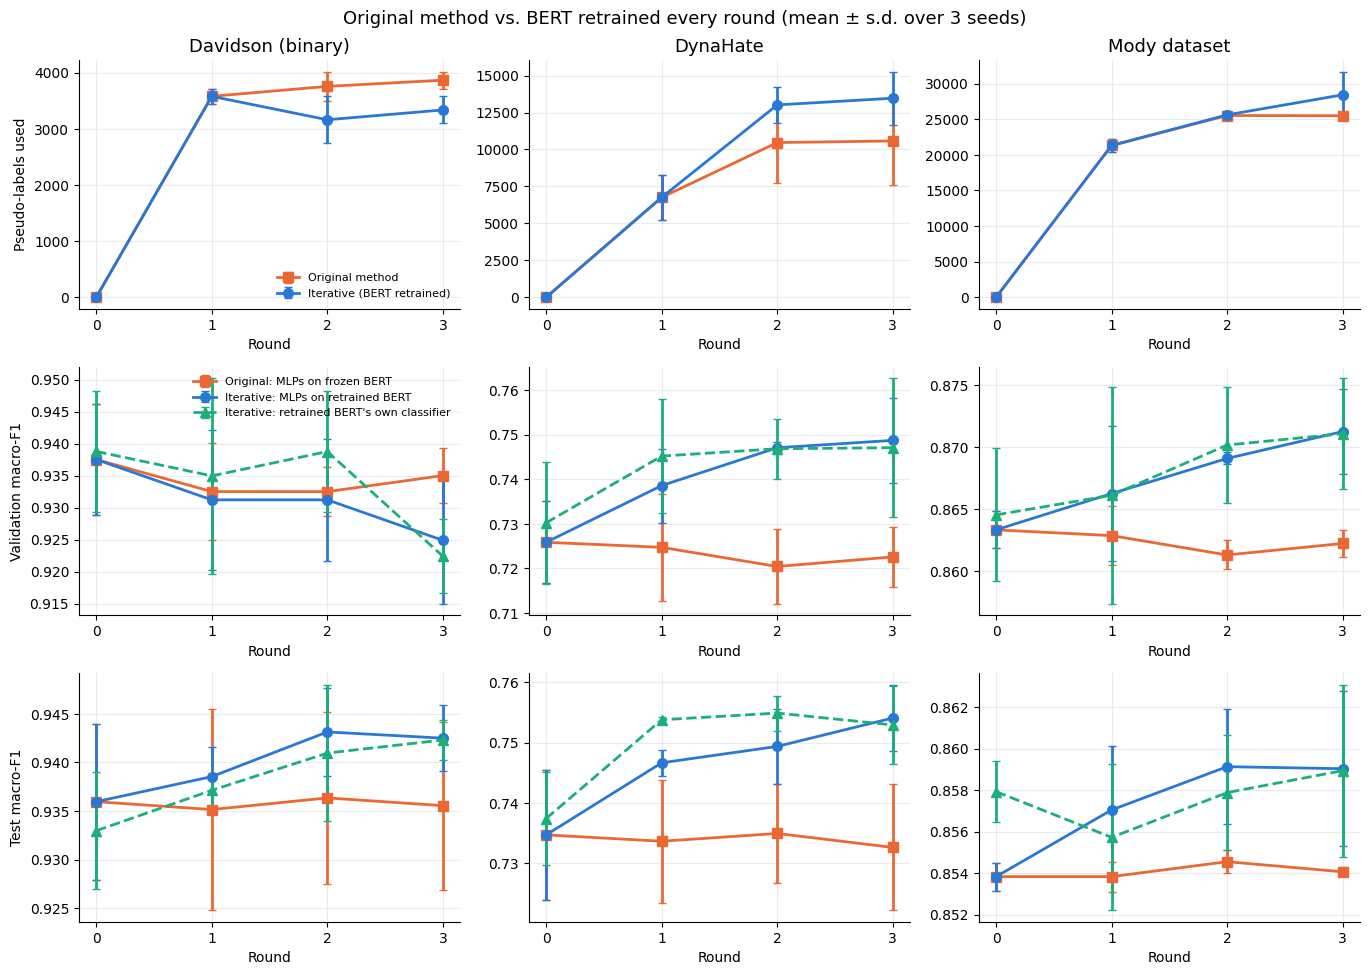

Round 0 vs the final round (macro-F1; gain in points, paired by seed):


,dataset,method,model,split,round 0,round 3,gain (pts),gain s.d.,seeds better
0,davidson,original,MLP ensemble,val,0.9375,0.9350,-0.2508,0.4318,0/3
1,davidson,original,MLP ensemble,test,0.9360,0.9355,-0.0409,0.1375,1/3
2,davidson,iterative,MLP ensemble,val,0.9375,0.9249,-1.2620,1.6964,1/3
3,davidson,iterative,MLP ensemble,test,0.9360,0.9425,0.6541,1.1006,2/3
4,davidson,iterative,BERT classifier,val,0.9388,0.9224,-1.6372,1.2133,0/3
5,davidson,iterative,BERT classifier,test,0.9330,0.9423,0.9345,0.7548,3/3
6,dynahate,original,MLP ensemble,val,0.7259,0.7226,-0.3278,0.2533,0/3
7,dynahate,original,MLP ensemble,test,0.7347,0.7326,-0.2083,0.1794,0/3
8,dynahate,iterative,MLP ensemble,val,0.7259,0.7487,2.2847,0.1055,3/3
9,dynahate,iterative,MLP ensemble,test,0.7347,0.7541,1.9389,0.7589,3/3


Per round, mean over seeds:


pseudo_labels  val_mlp  test_mlp  val_bert  \
dataset  method    round                                               
davidson original  0             0.0000   0.9375    0.9360    0.9388   
                   1          3578.6667   0.9325    0.9351       NaN   
                   2          3756.0000   0.9325    0.9363       NaN   
                   3          3866.0000   0.9350    0.9355       NaN   
         iterative 0             0.0000   0.9375    0.9360    0.9388   
                   1          3578.6667   0.9312    0.9385    0.9350   
                   2          3161.3333   0.9312    0.9431    0.9388   
                   3          3336.0000   0.9249    0.9425    0.9224   
dynahate original  0             0.0000   0.7259    0.7347    0.7302   
                   1          6760.0000   0.7247    0.7336       NaN   
                   2         10469.3333   0.7204    0.7349       NaN   
                   3         10576.6667   0.7226    0.7326       NaN   
         iterative 0             0.0000   0.7259    0.7347    0.7302   
                   1          6760.0000   0.7386    0.7466    0.7452   
                   2         13015.3333   0.7471    0.7494    0.7468   
                   3         13468.0000   0.7487    0.7541    0.7471   
original original  0             0.0000   0.8633    0.8538    0.8645   
                   1         21315.3333   0.8629    0.8538       NaN   
                   2         25525.3333   0.8613    0.8546       NaN   
                   3         25494.6667   0.8622    0.8541       NaN   
         iterative 0             0.0000   0.8633    0.8538    0.8645   
                   1         21315.3333   0.8663    0.8570    0.8661   
                   2         25610.6667   0.8691    0.8591    0.8702   
                   3         28430.6667   0.8713    0.8590    0.8711   

                          test_bert  
dataset  method    round             
davidson original  0         0.9330  
                   1            NaN  
                   2            NaN  
                   3            NaN  
         iterative 0         0.9330  
                   1         0.9371  
                   2         0.9410  
                   3         0.9423  
dynahate original  0         0.7374  
                   1            NaN  
                   2            NaN  
                   3            NaN  
         iterative 0         0.7374  
                   1         0.7538  
                   2         0.7549  
                   3         0.7529  
original original  0         0.8579  
                   1            NaN  
                   2            NaN  
                   3            NaN  
         iterative 0         0.8579  
                   1         0.8557  
                   2         0.8579  
                   3         0.8589

Saved:
  /kaggle/working/bert_once_cached_mlp/iterative/rounds.csv
  /kaggle/working/bert_once_cached_mlp/iterative/summary.csv
  /kaggle/working/bert_once_cached_mlp/iterative/rounds_chart.png


In [13]:
R = pd.read_csv(ITER_DIR/'rounds.csv') if (ITER_DIR/'rounds.csv').exists() else pd.DataFrame()
if R.empty:
    print('No finished runs yet.')
else:
    # Lines: (method, metric column suffix, label, colour, marker, dash). Colours follow the earlier figures.
    LINES = [('original', 'mlp', 'Original: MLPs on frozen BERT', '#eb6834', 's', '-'),
             ('iterative', 'mlp', 'Iterative: MLPs on retrained BERT', '#2a78d6', 'o', '-'),
             ('iterative', 'bert', "Iterative: retrained BERT's own classifier", '#1baf7a', '^', '--')]
    splits = [s for s in ('val', 'test') if f'{s}_mlp' in R]
    datasets_p = [d for d in DATASETS if d in set(R.dataset)]
    nseeds = R.groupby('dataset').seed.nunique().max()
    fig, axes = plt.subplots(1+len(splits), len(datasets_p), figsize=(4.6*len(datasets_p), 3.3*(1+len(splits))), squeeze=False)
    for j, ds in enumerate(datasets_p):
        D = R[R.dataset == ds]
        for method, color, marker, dash, label in [('original', '#eb6834', 's', '-', 'Original method'), ('iterative', '#2a78d6', 'o', '-', 'Iterative (BERT retrained)')]:
            g = D[D.method == method].groupby('round').pseudo_labels.agg(['mean', 'std'])
            axes[0, j].errorbar(g.index, g['mean'], yerr=g['std'].fillna(0) if nseeds > 1 else None, color=color, marker=marker,
                                ls=dash, lw=2, ms=7, capsize=3, label=label)
        axes[0, j].set_title(TITLES.get(ds, ds), fontsize=13)
        for i, split in enumerate(splits, start=1):
            for method, kind, label, color, marker, dash in LINES:
                g = D[D.method == method].groupby('round')[f'{split}_{kind}'].agg(['mean', 'std']).dropna(subset=['mean'])
                if g.empty: continue
                axes[i, j].errorbar(g.index, g['mean'], yerr=g['std'].fillna(0) if nseeds > 1 else None, color=color, marker=marker,
                                    ls=dash, lw=2, ms=7, capsize=3, label=label)
    axes[0, 0].set_ylabel('Pseudo-labels used')
    for i, split in enumerate(splits, start=1):
        axes[i, 0].set_ylabel(f"{'Validation' if split == 'val' else 'Test'} macro-F1")
    for ax in axes.ravel():
        ax.set_xlabel('Round'); ax.set_xticks(range(int(R['round'].max())+1)); ax.grid(alpha=.25)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0, 0].legend(frameon=False, fontsize=8, loc='lower right'); axes[1, 0].legend(frameon=False, fontsize=8, loc='best')
    fig.suptitle(f'Original method vs. BERT retrained every round (mean{" ± s.d." if nseeds > 1 else ""} over {nseeds} seed{"s" if nseeds > 1 else ""})', fontsize=13)
    plt.tight_layout(); plt.savefig(ITER_DIR/'rounds_chart.png', dpi=200); plt.show(); plt.close()

    # Round 0 vs the final round, paired by seed.
    rows = []
    for (ds, method), D in R.groupby(['dataset', 'method'], sort=False):
        last = D['round'].max()
        for kind in ('mlp', 'bert'):
            for split in splits:
                col = f'{split}_{kind}'
                a = D[D['round'] == 0].set_index('seed')[col]; b = D[D['round'] == last].set_index('seed')[col]
                gain = ((b - a)*100).dropna()
                if gain.empty: continue
                rows.append({'dataset': ds, 'method': method, 'model': 'MLP ensemble' if kind == 'mlp' else 'BERT classifier',
                             'split': split, 'round 0': a.mean(), f'round {last}': b.mean(), 'gain (pts)': gain.mean(),
                             'gain s.d.': gain.std(ddof=1) if len(gain) > 1 else np.nan, 'seeds better': f'{int((gain > 0).sum())}/{len(gain)}'})
    S = pd.DataFrame(rows); S.to_csv(ITER_DIR/'summary.csv', index=False)
    print('Round 0 vs the final round (macro-F1; gain in points, paired by seed):')
    display(S.round(4))
    print('Per round, mean over seeds:')
    display(R.groupby(['dataset', 'method', 'round'], sort=False)[[c for c in R if c.endswith(('_mlp', '_bert')) or c == 'pseudo_labels']].mean().round(4))
    print('Saved:', ITER_DIR/'rounds.csv', ITER_DIR/'summary.csv', ITER_DIR/'rounds_chart.png', sep='\n  ')

## How to read the chart
- **Orange (original):** BERT stays frozen; only the MLPs learn from the pseudo-labels.
- **Blue (iterative MLPs):** the same framework, but each round runs on embeddings from a BERT retrained on that round's pseudo-labels.
- **Green dashed (iterative BERT):** that retrained BERT classifying on its own.
- **Round 0 is identical** for orange and blue, so any difference afterwards comes only from retraining BERT.
- **Use the test row to decide.** Validation sets are small (Davidson has 267 rows), so validation lines jump around. If blue or green rises above orange on test across seeds, retraining BERT each round helps; the summary table gives the paired gain and how many seeds improved.